# Deteksi Transaksi Fraud Kartu Kredit Menggunakan Metode Klasifikasi

**Notebook:** Business Understanding, Data Gathering, EDA, Data Cleaning, Preprocessing, Seleksi Fitur, Modeling, Evaluasi, dan Konklusi
**Mata kuliah:** Data Science (IF-A) | **Dosen pengampu:** Dhimas Arief Dharmawan

| No | Nama | NIM |
|----|------|-----|
| 1 | Farabian Nabil Alauzi | 123240058 |
| 2 | Waladi Lintang Novianto | 123240065 |
| 3 | Raflin Madani | 123240078 |
| 4 | Raihan Buono Putra | 123240090 |

Program Studi Informatika, Fakultas Teknik Industri, Universitas Pembangunan Nasional "Veteran" Yogyakarta, 2026

---

**Daftar isi**
1. Business Understanding
2. Data Gathering
3. Exploratory Data Analysis (EDA)
4. Data Cleaning
5. Preprocessing
6. Seleksi Fitur
7. Modeling
8. Evaluasi
9. Konklusi

Notebook terpadu ini dikembangkan dari setupV2.ipynb dan eksperimen seleksi fitur. Gunakan Python dengan pandas, numpy, matplotlib, seaborn, scipy, scikit-learn, dan Jupyter. Letakkan creditcard_1000.csv di folder yang sama, lalu jalankan Run All.

## Keterkaitan dengan presentasi kelompok

PPT menjadi ringkasan tiap tahap pengerjaan. Notebook terpadu melanjutkan cakupan Progress 2 sampai modeling, evaluasi, dan konklusi sesuai panduan proyek akhir.

| Presentasi | Materi | Bagian notebook |
|---|---|---|
| Progress 1, slide 2-3 | Masalah fraud, stakeholder, dan penandaan transaksi untuk analis | Bab 1.1-1.2 |
| Progress 1, slide 4-8 | SMART, kriteria keberhasilan, asumsi, risiko, etika, dan nilai bisnis | Bab 1.3-1.7 |
| Progress 1, slide 9 | Pemetaan kebutuhan stakeholder dengan data | Tabel pemetaan di bab 1 |
| Progress 2, slide 2-3 | Sumber, lisensi, 1.000 transaksi kerja, dan data dictionary | Bab 2 |
| Progress 2, slide 4-10 | Audit awal, statistik, distribusi, korelasi, dan bias sampel | Bab 3 |
| Progress 2, slide 11-12 | Penghapusan 19 duplikat dan perbandingan 1.000 ke 981 transaksi | Bab 4 |
| Progress 2, slide 13-14 | Encoding, scaling, imbalance, dan split 784/197 | Bab 5 |
| Progress 2, slide 15 | Keputusan penggunaan fitur | Bab 6, alasan berdasarkan eksperimen notebook |
| Pengembangan proyek akhir | Perbandingan SVM dan Random Forest, evaluasi, dan konklusi | Bab 7-9 |

PPT rujukan tersedia di [Progress 1](rujukan/ppt/Progress%201%20Business%20Understanding%20Data%20Science.pdf) dan [Progress 2](rujukan/ppt/Progress%202%20Data%20Understanding%20Data%20Science.pdf). Panduan ada di folder **rujukan/panduan proyek**, dan modul praktikum di **rujukan/modul**.

Angka statistik di bab 3 menggunakan 1.000 transaksi sebelum cleaning. Bab 4 menjelaskan perubahan ke 981 transaksi. Bab 6 dan seterusnya mempelajari parameter dari 784 transaksi latih. Studi sampel acak 100.000 pada bab 3 merupakan pemeriksaan terpisah terhadap dataset penuh.

# 1. Business Understanding

## 1.1 Latar Belakang dan Permasalahan Bisnis

Transaksi kartu kredit semakin banyak digunakan dalam aktivitas keuangan digital. Namun, penggunaannya juga memiliki risiko terjadinya penipuan (*credit card fraud*) yang dapat menimbulkan kerugian finansial. Oleh karena itu, diperlukan pendekatan berbasis data untuk membantu mengidentifikasi transaksi yang terindikasi sebagai penipuan.

Salah satu pendekatan yang dapat digunakan adalah data science melalui pemodelan klasifikasi. Dengan memanfaatkan data historis transaksi, pola transaksi dapat dianalisis untuk memahami karakteristik transaksi normal dan transaksi fraud.

**Permasalahan bisnis:** bagaimana mengidentifikasi transaksi kartu kredit yang terindikasi fraud dari data historis, sehingga penerbit kartu dapat menekan kerugian tanpa terlalu banyak menolak transaksi yang sah. Permasalahan ini dirumuskan sebagai **klasifikasi biner**: `Class = 1` (fraud) dan `Class = 0` (normal).

**Rumusan masalah**
1. Bagaimana memahami permasalahan bisnis dan kebutuhan analisis dalam mendeteksi transaksi kartu kredit yang terindikasi fraud?
2. Bagaimana memahami karakteristik, struktur, dan kualitas dataset *Credit Card Fraud Detection* serta menyiapkannya untuk pemodelan?

3. Bagaimana perbandingan SVM linear dan Random Forest dalam mendeteksi fraud?
4. Apa dampak pengurangan fitur terhadap PR-AUC validasi Random Forest?

**Tujuan penulisan**
1. Melakukan Business Understanding untuk mengidentifikasi permasalahan bisnis dan kebutuhan analisis dalam deteksi fraud.
2. Melakukan Data Gathering, EDA, Cleaning, dan Preprocessing sehingga data siap dipakai pada tahap pemodelan.
3. Membandingkan SVM linear dan Random Forest dengan validasi silang dan evaluasi data uji.
4. Mengukur dampak pengurangan fitur terhadap PR-AUC Random Forest.

## 1.2 Pemangku Kepentingan (Stakeholders)

| No | Pemangku Kepentingan | Peran | Kepentingan terhadap Proyek |
|----|----------------------|-------|-----------------------------|
| 1 | Penerbit kartu (bank/lembaga keuangan) | Pengguna utama hasil analisis | Menekan kerugian akibat transaksi fraud, menjaga reputasi, dan memenuhi kewajiban pengelolaan risiko |
| 2 | Tim analis fraud / manajemen risiko | Pengguna operasional | Mendapatkan prioritas transaksi berisiko tinggi agar peninjauan manual lebih efisien dan terarah |
| 3 | Pemegang kartu (nasabah) | Pihak yang terdampak langsung | Terlindungi dari penyalahgunaan kartu, sekaligus tidak mengalami penolakan transaksi sah yang tidak perlu |
| 4 | Merchant | Pihak yang terdampak | Mengurangi kerugian akibat *chargeback* dan menjaga kelancaran transaksi pelanggan |
| 5 | Tim data science (penulis) | Pelaksana proyek | Memahami masalah dan data, serta menyiapkan dasar yang tepat untuk preprocessing dan pemodelan |
| 6 | Dosen pengampu dan Program Studi Informatika | Pemberi tugas dan penilai | Menilai pemahaman penerapan alur CRISP-DM pada kasus nyata |
| 7 | Penyedia dataset (ULB Machine Learning Group) | Pemilik data | Data digunakan sesuai informasi lisensi dan untuk tujuan akademik |

Karena proyek berskala akademik, pemangku kepentingan nomor 1-4 adalah pihak yang dibayangkan (*hypothetical*) dalam skenario bisnis, sedangkan nomor 5-7 terlibat langsung dalam pelaksanaan proyek.

### Pemetaan stakeholder dan data

| Stakeholder | Kebutuhan | Kolom pendukung analisis | Kegunaan hasil |
|---|---|---|---|
| Bank / penerbit kartu | Mengenali transaksi berisiko fraud | Time, Amount, V1-V28; Class sebagai label historis | Mendukung pengelolaan risiko dan peninjauan |
| Tim fraud / risk analyst | Menentukan prioritas pemeriksaan | Seluruh fitur prediktor serta label Class saat pelatihan/evaluasi | Mengurutkan transaksi yang memerlukan pemeriksaan |
| Pemegang kartu | Mengurangi penyalahgunaan dan gangguan transaksi sah | Amount, Time, Class dalam analisis historis | Mendapat manfaat dari deteksi yang lebih tepat |
| Merchant | Mengurangi potensi kerugian dan gangguan transaksi | Amount, Time, Class dalam analisis historis | Mendapat manfaat dari berkurangnya transaksi fraud |
| Tim data science | Memeriksa kualitas data dan membangun model | Seluruh 31 kolom pada analisis historis | Melakukan EDA, preprocessing, pelatihan, dan evaluasi |

Class digunakan sebagai jawaban historis untuk belajar dan mengevaluasi. Saat transaksi baru diprediksi, input model terdiri dari 30 fitur. Stakeholder operasional memakai hasil penilaian risiko model untuk membantu peninjauan.

## 1.3 Tujuan SMART

**Tujuan 1 - Pemahaman bisnis dan data (Progress 1)**

| Aspek | Uraian |
|-------|--------|
| Specific | Menyusun Business Understanding dan Data Understanding untuk dataset Credit Card Fraud Detection: pemangku kepentingan, tujuan, asumsi, risiko, struktur data, kualitas data, dan EDA |
| Measurable | Kualitas data terdokumentasi (missing value, duplikat, kandidat outlier) dan rasio kelas teridentifikasi (492 fraud dari 284.807 transaksi pada dataset lengkap) |
| Achievable | Dataset tersedia terbuka di Kaggle, berstruktur tabular, dan tidak memiliki missing value sehingga dapat dianalisis dengan pandas, numpy, matplotlib, dan seaborn |
| Relevant | Menjadi dasar keputusan preprocessing, pemilihan model, dan metrik evaluasi |
| Time-bound | Diselesaikan pada laporan Progress 1 sesuai jadwal progress report |

**Tujuan 2 - Persiapan data (notebook ini)**

| Aspek | Uraian |
|-------|--------|
| Specific | Melakukan Data Gathering, EDA, Cleaning, dan Preprocessing pada `creditcard_1000.csv` (subset 1.000 transaksi) |
| Measurable | Missing value, duplikat, dan kandidat outlier terdokumentasi dan ditangani dengan alasan yang jelas; data dibagi secara stratified menjadi bagian latih dan uji untuk pemodelan |
| Achievable | Menggunakan pandas, scikit-learn, matplotlib, dan seaborn pada data tabular berukuran kecil |
| Relevant | Data yang bersih dan bebas kebocoran (*leakage*) merupakan prasyarat pemodelan yang valid |
| Time-bound | Diselesaikan dan dikumpulkan sebagai repository GitHub sebelum tenggat pengumpulan tugas di Spada |

**Tujuan 3 - Pemodelan dan evaluasi (proyek akhir)**

| Aspek | Uraian |
|-------|--------|
| Specific | Membangun model klasifikasi biner untuk membedakan transaksi fraud (`Class = 1`) dan normal (`Class = 0`) |
| Measurable | Dievaluasi dengan precision, recall, F1-score, dan AUPRC pada data uji, serta dibandingkan dengan model baseline |
| Achievable | Subset kerja hampir seimbang; gunakan stratified split dan validasi silang tanpa resampling tambahan |
| Relevant | Mendukung kebutuhan bisnis mendeteksi fraud secara dini dengan tetap meminimalkan penolakan transaksi sah |
| Time-bound | Diselesaikan sebelum tenggat proyek akhir pada 22 November 2026 |

## 1.4 Kriteria Keberhasilan

**a. Keberhasilan bisnis**
1. Permasalahan bisnis terumuskan dengan jelas sebagai klasifikasi biner untuk mengidentifikasi transaksi fraud.
2. Pemangku kepentingan, manfaat, risiko, serta batasan proyek terdokumentasi secara eksplisit.
3. Hasil analisis dapat dijadikan dasar untuk memprioritaskan transaksi berisiko tinggi agar peninjauan lebih efisien.

**b. Keberhasilan pemahaman dan persiapan data**
1. Struktur dataset (jumlah baris, kolom, dan tipe data) terdokumentasi lengkap dalam data dictionary.
2. Pemeriksaan kualitas data selesai: missing value, duplikat, dan kandidat outlier.
3. Proporsi kelas teridentifikasi dan dijadikan pertimbangan dalam pemilihan metrik.
4. Keputusan cleaning dan preprocessing diambil berdasarkan temuan EDA, tanpa menghapus duplikat atau outlier secara sembarangan.

**c. Keberhasilan model**
1. Evaluasi tidak bertumpu pada akurasi, melainkan pada precision, recall, F1-score, dan AUPRC.
2. Model harus lebih baik daripada baseline sederhana (misalnya memprediksi seluruh transaksi sebagai normal) pada AUPRC dan recall kelas fraud.
3. Laporkan false negative dan false positive pada ambang bawaan model. Penentuan biaya kerugian dan threshold operasional memerlukan informasi bisnis tambahan.
4. Hasil dapat direproduksi mengikuti notebook ini.

## 1.5 Asumsi dan Batasan Proyek

**Asumsi**
1. Label pada kolom `Class` dianggap akurat (1 = fraud, 0 = normal). Proses pelabelan oleh penyedia dataset tidak diverifikasi ulang.
2. Setiap baris mewakili satu transaksi kartu kredit yang berdiri sendiri.
3. Subset digunakan untuk mempelajari alur klasifikasi pada dataset ini; keterwakilannya dibahas melalui bias proporsi kelas, waktu, dan wilayah.
4. Fitur `V1`-`V28` dianggap telah melalui transformasi PCA sesuai dokumentasi dataset, sedangkan `Time` dan `Amount` masih berada pada skala aslinya sehingga memerlukan penyesuaian skala.
5. Data duplikat dan kandidat outlier belum tentu merupakan kesalahan data, sehingga penanganannya diputuskan berdasarkan pertimbangan analisis.

**Batasan**
1. **Cakupan tahapan:** notebook ini mencakup Business Understanding sampai Konklusi, termasuk seleksi fitur serta perbandingan SVM dan Random Forest.
2. **Cakupan waktu dan wilayah:** transaksi pemegang kartu di Eropa selama dua hari pada September 2013, sehingga belum tentu menggambarkan pola fraud pada kondisi lain.
3. **Anonimisasi fitur:** `V1`-`V28` hasil PCA sehingga makna bisnisnya tidak dapat diinterpretasikan langsung.
4. **Keterbatasan atribut:** tidak ada informasi jenis merchant, lokasi, perangkat, maupun riwayat pemegang kartu.
5. **Subset data:** dataset lengkap berisi 284.807 transaksi dengan hanya 492 fraud (sekitar 0,17%). Notebook ini memakai subset 1.000 baris (semua fraud ditambah transaksi normal yang dipilih acak), sehingga proporsi kelas **tidak lagi mencerminkan kondisi nyata**. Metrik yang diperoleh dari subset ini cenderung terlalu optimistis dibanding kondisi produksi.
6. **Sifat analisis:** analisis *offline* pada data historis, tanpa implementasi sistem deteksi *real-time*.
7. **Lisensi data:** mengikuti informasi lisensi pada Kaggle dan terbatas untuk kepentingan akademik.

## 1.6 Risiko dan Mitigasi

| No | Risiko | Dampak | Mitigasi |
|----|--------|--------|----------|
| 1 | Ketidakseimbangan kelas ekstrem (pada dataset lengkap) | Model memprediksi semua transaksi sebagai normal dan tetap tampak akurat | Gunakan precision, recall, F1-score, AUPRC; pertimbangkan class weight/resampling dan *stratified split* |
| 2 | Data duplikat | Bias dan kebocoran data bila baris yang sama muncul pada data latih dan uji | Evaluasi duplikat sebelum dihapus; pastikan data latih dan uji tidak tumpang tindih |
| 3 | Kandidat outlier yang banyak (mis. `Amount`) | Penghapusan sembarangan dapat membuang transaksi fraud bernilai ekstrem | Jangan hapus otomatis; telaah dulu dan gunakan penskalaan yang *robust* |
| 4 | Fitur teranonimkan (PCA) | Hasil model sulit dijelaskan secara bisnis | Fokus pada performa dan pola umum; catat keterbatasan interpretabilitas |
| 5 | Data tidak representatif (dua hari, Eropa, 2013, dan subset 1.000 baris) | Hasil berpotensi tidak berlaku pada data lain | Nyatakan batas generalisasi; uji ulang dengan data yang lebih baru/realistis |
| 6 | Kesalahan klasifikasi (FN dan FP) | FN membuat fraud lolos; FP menambah alarm keliru dan beban peninjauan transaksi sah | Laporkan precision, recall, FN, dan FP; pengaturan threshold berbasis biaya menjadi pekerjaan lanjutan |
| 7 | *Overfitting* pada kelas minoritas | Model baik pada data latih, buruk pada data baru | Pisahkan data latih/uji dengan tepat, gunakan validasi silang |
| 8 | Perubahan pola fraud (*concept drift*) | Performa menurun pada kondisi nyata | Rekomendasikan pemantauan dan pelatihan ulang berkala |

**Etika dan penggunaan data.** Gunakan dataset sesuai ketentuan sumber, cantumkan atribusi, dan jaga kerahasiaan data jika kelak memakai data operasional. Fitur anonim tetap memiliki batas interpretasi. Penerapan model mendukung pemeriksaan analis. Kebocoran informasi data uji dalam pelatihan dan pengungkapan data pribadi memiliki dampak serta mitigasi yang berbeda.

## 1.7 Manfaat dan Nilai Bisnis

1. **Mengurangi kerugian finansial:** identifikasi transaksi mencurigakan lebih dini membantu menekan kerugian penerbit kartu, merchant, dan pemegang kartu.
2. **Meningkatkan efisiensi pemeriksaan:** model membantu memprioritaskan transaksi berisiko tinggi untuk ditinjau analis fraud, karena pemeriksaan manual atas semua transaksi tidak praktis.
3. **Menjaga kepercayaan pelanggan:** deteksi yang akurat melindungi pemegang kartu sekaligus meminimalkan penolakan transaksi sah.
4. **Mendukung keputusan berbasis data:** pemahaman karakteristik dan kualitas data menjadi dasar objektif untuk preprocessing, pemilihan model, dan metrik.
5. **Nilai pembelajaran akademik:** contoh penerapan alur CRISP-DM pada kasus nyata yang *imbalanced*.

> Manfaat di atas bersifat potensial, bukan hasil terukur. Nilai finansial sesungguhnya baru dapat dihitung setelah model dibangun dan dievaluasi.

**Use case utama.** Menandai transaksi yang berisiko agar tim fraud dapat menentukan prioritas pemeriksaan lebih lanjut, sesuai Progress 1.

# 2. Data Gathering

## 2.1 Sumber Data dan Lisensi

Dataset yang digunakan adalah **Credit Card Fraud Detection** dari Kaggle, dipublikasikan oleh Machine Learning Group, Universite Libre de Bruxelles (ULB). Isinya transaksi kartu kredit pemegang kartu di Eropa selama dua hari pada September 2013. Informasi lisensi pada Kaggle: *Database: Open Database, Contents: Database Contents*.

- Tautan: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
- Dataset lengkap: 284.807 transaksi (492 fraud, 284.315 normal), 31 kolom.

## 2.2 Dataset Kerja (`creditcard_1000.csv`)

Untuk tugas ini digunakan subset **1.000 transaksi**: seluruh 492 transaksi fraud dari dataset lengkap ditambah 508 transaksi normal yang dipilih acak (`random_state=42`). Baris duplikat bawaan dataset asli **tidak dihapus** agar dapat dinilai pada tahap cleaning. Subset dibuat dengan kode berikut (tidak dijalankan di notebook ini karena memerlukan `creditcard.csv` lengkap):

```python
df_full = pd.read_csv("creditcard.csv")
fraud = df_full[df_full["Class"] == 1]
normal = df_full[df_full["Class"] == 0].sample(n=1000 - len(fraud), random_state=42)
pd.concat([fraud, normal]).sort_index().to_csv("creditcard_1000.csv", index=False)
```

## 2.3 Data Dictionary

| No | Kolom | Tipe | Deskripsi |
|----|-------|------|-----------|
| 1 | `Time` | Numerik | Waktu transaksi dalam detik sejak transaksi pertama dalam dataset |
| 2-29 | `V1` - `V28` | Numerik | Fitur hasil transformasi PCA (dianonimkan untuk menjaga kerahasiaan) |
| 30 | `Amount` | Numerik | Nominal transaksi (satuan mata uang tidak dinyatakan pada file) |
| 31 | `Class` | Numerik (biner) | Variabel target: 0 = transaksi normal, 1 = fraud |

**Pembedaan desain sampel.** Subset 1.000 baris diperkaya kelas fraud. Analisis sampel acak 100.000 baris pada notebook UTS merupakan analisis terpisah. Notebook terpadu ini memakai subset 1.000 baris secara konsisten.

**Penggunaan kamus data.** Time diukur dalam detik sejak transaksi pertama. Amount adalah nominal transaksi; berkas CSV dan kamus data proyek tidak menetapkan USD sebagai unitnya. Seluruh prediktor numerik, dan Class adalah label biner.

## IMPORT Library

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, StandardScaler

RANDOM_STATE = 42
pd.set_option("display.max_columns", 35)
pd.set_option("display.max_colwidth", 110)
sns.set_theme(style="whitegrid", context="notebook")

## IMPORT DATA

In [4]:
candidate_paths = [Path("creditcard_1000.csv"), Path("Credit-Card-Fraud-Detection/creditcard_1000.csv")]
data_path = next((path for path in candidate_paths if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError("Letakkan creditcard_1000.csv di folder notebook sebelum menjalankan Run All.")
df = pd.read_csv(data_path)
required = ["Time"] + [f"V{i}" for i in range(1, 29)] + ["Amount", "Class"]
if set(df.columns) != set(required) or set(df["Class"].unique()) != {0, 1}:
    raise ValueError("Periksa 31 kolom yang diharapkan dan label Class 0/1.")
display(df.head())
df.info()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,406.0,-2.312227,1.951992,-1.609851,3.997906,-0.522188,-1.426545,-2.537387,1.391657,-2.770089,-2.772272,3.202033,-2.899907,-0.595222,-4.289254,0.389724,-1.140747,-2.830056,-0.016822,0.416956,0.126911,0.517232,-0.035049,-0.465211,0.320198,0.044519,0.177840,0.261145,-0.143276,0.00,1
1,472.0,-3.043541,-3.157307,1.088463,2.288644,1.359805,-1.064823,0.325574,-0.067794,-0.270953,-0.838587,-0.414575,-0.503141,0.676502,-1.692029,2.000635,0.666780,0.599717,1.725321,0.283345,2.102339,0.661696,0.435477,1.375966,-0.293803,0.279798,-0.145362,-0.252773,0.035764,529.00,1
2,607.0,1.038261,-0.301415,0.910167,0.863872,-0.741702,0.090125,-0.409753,0.076723,0.684990,-0.306226,-0.402137,0.924804,0.836035,-0.450042,0.242100,-0.337570,0.119845,-0.716554,-0.447645,0.040056,0.134996,0.554309,-0.138944,0.168500,0.423859,0.530611,0.014980,0.028041,69.99,0
3,861.0,-0.945987,1.232753,0.820313,0.311064,0.981736,0.935188,0.566926,-0.008604,-0.621912,0.380949,0.454998,0.813052,1.348536,0.012636,0.714735,-0.007153,-0.796042,0.403174,0.913516,-0.044043,0.124922,0.284644,-0.197951,-1.326061,-0.161715,-0.382919,-0.488500,0.144470,10.00,0
4,1308.0,-1.379848,0.536720,2.647870,1.408111,0.126442,0.986525,0.960251,-0.629717,1.729173,1.346832,-0.622458,0.516210,0.174168,-2.023273,-1.185043,-2.036791,0.653358,-1.294348,1.297445,0.464675,-0.666874,-0.343574,0.022138,0.093532,0.011293,-0.503395,-0.438189,-0.346731,43.80,0


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Time    1000 non-null   float64
 1   V1      1000 non-null   float64
 2   V2      1000 non-null   float64
 3   V3      1000 non-null   float64
 4   V4      1000 non-null   float64
 5   V5      1000 non-null   float64
 6   V6      1000 non-null   float64
 7   V7      1000 non-null   float64
 8   V8      1000 non-null   float64
 9   V9      1000 non-null   float64
 10  V10     1000 non-null   float64
 11  V11     1000 non-null   float64
 12  V12     1000 non-null   float64
 13  V13     1000 non-null   float64
 14  V14     1000 non-null   float64
 15  V15     1000 non-null   float64
 16  V16     1000 non-null   float64
 17  V17     1000 non-null   float64
 18  V18     1000 non-null   float64
 19  V19     1000 non-null   float64
 20  V20     1000 non-null   float64
 21  V21     1000 non-null   float64
 22  V22     1000

# 3. Exploratory Data Analysis (EDA)

## 3.1 Gambaran Umum Dataset

In [5]:
# Cek Dataset
print(f"Ukuran Dataset: {df.shape} \n")

print(f"Tipe Data :")
df.info()

print("\nStatistik Deskriptif: ")
display(df.describe().T)

Ukuran Dataset: (1000, 31) 

Tipe Data :
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Time    1000 non-null   float64
 1   V1      1000 non-null   float64
 2   V2      1000 non-null   float64
 3   V3      1000 non-null   float64
 4   V4      1000 non-null   float64
 5   V5      1000 non-null   float64
 6   V6      1000 non-null   float64
 7   V7      1000 non-null   float64
 8   V8      1000 non-null   float64
 9   V9      1000 non-null   float64
 10  V10     1000 non-null   float64
 11  V11     1000 non-null   float64
 12  V12     1000 non-null   float64
 13  V13     1000 non-null   float64
 14  V14     1000 non-null   float64
 15  V15     1000 non-null   float64
 16  V16     1000 non-null   float64
 17  V17     1000 non-null   float64
 18  V18     1000 non-null   float64
 19  V19     1000 non-null   float64
 20  V20     1000 non-null   float64
 21  V21     

,count,mean,std,min,25%,50%,75%,max
Time,1000.0,88105.316000,48076.754070,406.000000,46099.750000,81348.000000,134766.750000,171917.000000
V1,1000.0,-2.269096,5.490748,-30.552380,-2.732232,-0.741705,1.134074,2.351891
V2,1000.0,1.782844,3.659953,-8.402154,-0.173693,0.903714,2.777569,22.057729
V3,1000.0,-3.479627,6.168222,-31.103685,-5.049001,-1.326710,0.242719,3.143387
V4,1000.0,2.224461,3.198678,-4.519509,-0.177790,1.275632,4.173330,12.114672
V5,1000.0,-1.521588,4.177193,-22.105532,-1.736819,-0.336980,0.493738,11.095089
V6,1000.0,-0.715315,1.718498,-6.406267,-1.572363,-0.664051,0.080004,6.474115
V7,1000.0,-2.733041,5.810310,-43.557242,-3.028330,-0.608816,0.288919,5.802537
V8,1000.0,0.284916,4.821946,-41.044261,-0.229344,0.137477,0.855025,20.007208
V9,1000.0,-1.253420,2.332128,-13.434066,-2.331368,-0.695574,0.194952,5.232322


## 3.2 Distribusi Kelas

       Jumlah  Persentase (%)
Class                        
0         508            50.8
1         492            49.2


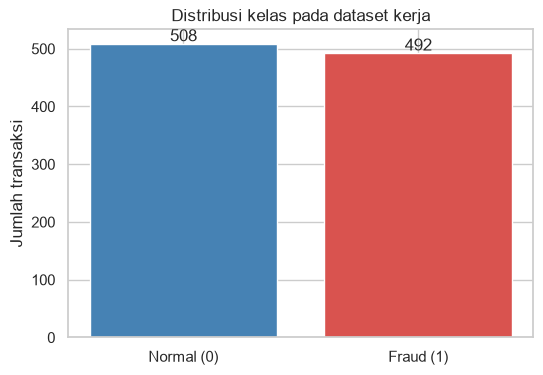

In [6]:
class_counts = df["Class"].value_counts().sort_index()
class_pct = df["Class"].value_counts(normalize=True).sort_index() * 100
print(pd.DataFrame({"Jumlah": class_counts, "Persentase (%)": class_pct.round(2)}))

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Normal (0)", "Fraud (1)"], class_counts.values, color=["#4682B4", "#D9534F"])
for b in bars:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 5, int(b.get_height()), ha="center")
ax.set_ylabel("Jumlah transaksi")
ax.set_title("Distribusi kelas pada dataset kerja")
plt.show()

Dataset kerja hampir seimbang karena merupakan hasil pengambilan **seluruh fraud** dan **sebagian transaksi normal**. Pada dataset lengkap proporsi fraud hanya sekitar 0,17%, jadi hasil EDA dan model dari subset ini tidak boleh langsung dianggap mewakili kondisi nyata.

### Representativitas dan bias sampel

Subset kerja berisi seluruh 492 fraud ditambah 508 transaksi normal yang dipilih acak. Proporsi fraud 49,2% pada subset tersebut berbeda dari sekitar 0,173% pada dataset penuh. Ringkasan korelasi dan metrik pemodelan perlu dibaca sesuai komposisi itu.

Progress 2 slide 6 juga memakai studi simple random sampling 100.000 transaksi dari dataset penuh sebagai analisis terpisah. Sel berikut menghitung proporsi kelas, interval Wilson 95%, standardized mean difference (SMD), dan statistik KS. Dataset lengkap creditcard.csv diperlukan untuk menghasilkan angka studi tersebut. Letakkan di folder archive pada proyek, folder notebook, atau lokasi yang diperiksa dalam sel.

Perbandingan terhadap seluruh data asal merupakan pemeriksaan deskriptif. Sampel berasal dari data penuh yang sama, sehingga hasil KS digunakan sebagai ukuran perbedaan distribusi. SMD kecil dan interval proporsi membantu menilai kedekatan numerik sampel terhadap data asal. Cakupan dua hari di Eropa pada 2013 tetap membatasi generalisasi.

,Dataset penuh,Sampel acak
Transaksi,284807.0000,100000.000
Fraud,492.0000,161.000
Fraud (%),0.1727,0.161


,SMD,KS statistic,|SMD|
Variabel,,,
V22,0.00435,0.00276,0.00435
V25,0.00431,0.00332,0.00431
V2,0.00406,0.00225,0.00406
Amount,-0.00346,0.00206,0.00346
V3,-0.00317,0.00294,0.00317
Class,-0.00288,0.00012,0.00288
V27,0.00279,0.00172,0.00279
V26,-0.00270,0.00255,0.00270
V6,0.00266,0.00288,0.00266


CI Wilson 95% untuk proporsi fraud sampel adalah **0.001380 sampai 0.001878**. SMD absolut maksimum **0.0044** dan **100%** variabel memiliki |SMD| di bawah 0,10. Indikator ini membandingkan sampel acak dengan dataset asal. Subset kerja yang diperkaya fraud tetap memiliki komposisi kelas yang berbeda.

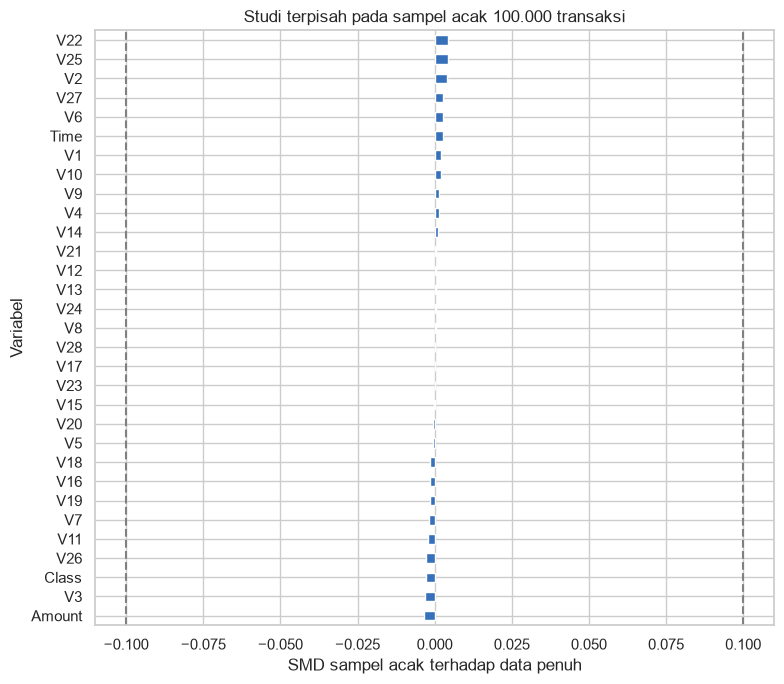

In [7]:
from scipy.stats import ks_2samp

full_candidates = [
    data_path.resolve().parent / "archive" / "creditcard.csv",
    data_path.resolve().parent.parent / "archive" / "creditcard.csv",
    data_path.resolve().parent / "creditcard.csv",
]
full_path = next((path for path in full_candidates if path.is_file()), None)
if full_path is None:
    display(Markdown(
        "**Studi 100.000 transaksi belum dijalankan pada komputer ini.** "
        "Tambahkan dataset lengkap creditcard.csv untuk menjalankannya. "
        "Analisis utama melanjutkan subset kerja 1.000 transaksi."
    ))
else:
    full_data = pd.read_csv(full_path)
    if len(full_data) < 100_000:
        raise ValueError("Studi pada PPT memerlukan dataset penuh untuk sampel 100.000 transaksi.")
    random_sample = full_data.sample(n=100_000, replace=False, random_state=RANDOM_STATE)
    n = len(random_sample)
    sample_rate = random_sample["Class"].mean()
    population_rate = full_data["Class"].mean()
    z = 1.96
    denominator = 1 + z**2 / n
    center = (sample_rate + z**2 / (2 * n)) / denominator
    margin = z * np.sqrt(sample_rate * (1 - sample_rate) / n + z**2 / (4 * n**2)) / denominator
    representation_rows = []
    for column in full_data.select_dtypes(include="number"):
        pooled_sd = np.sqrt((full_data[column].var(ddof=1) + random_sample[column].var(ddof=1)) / 2)
        smd = (random_sample[column].mean() - full_data[column].mean()) / pooled_sd
        representation_rows.append({
            "Variabel": column, "SMD": smd,
            "KS statistic": ks_2samp(full_data[column], random_sample[column]).statistic,
        })
    representation_table = pd.DataFrame(representation_rows).set_index("Variabel")
    representation_table["|SMD|"] = representation_table["SMD"].abs()
    representation_table = representation_table.sort_values("|SMD|", ascending=False)
    display(pd.DataFrame({
        "Dataset penuh": [len(full_data), int(full_data["Class"].sum()), population_rate * 100],
        "Sampel acak": [n, int(random_sample["Class"].sum()), sample_rate * 100],
    }, index=["Transaksi", "Fraud", "Fraud (%)"]).round(4))
    display(representation_table.round(5))
    maximum_smd = representation_table["|SMD|"].max()
    display(Markdown(
        f"CI Wilson 95% untuk proporsi fraud sampel adalah **{center-margin:.6f} sampai {center+margin:.6f}**. "
        f"SMD absolut maksimum **{maximum_smd:.4f}** dan "
        f"**{representation_table['|SMD|'].lt(.10).mean():.0%}** variabel memiliki |SMD| di bawah 0,10. "
        "Indikator ini membandingkan sampel acak dengan dataset asal. Subset kerja yang diperkaya fraud "
        "tetap memiliki komposisi kelas yang berbeda."
    ))
    fig, ax = plt.subplots(figsize=(8, 7))
    representation_table.sort_values("SMD")["SMD"].plot.barh(ax=ax, color="#3670BA")
    ax.axvline(-.10, color="gray", linestyle="--")
    ax.axvline(.10, color="gray", linestyle="--")
    ax.set(xlabel="SMD sampel acak terhadap data penuh", title="Studi terpisah pada sampel acak 100.000 transaksi")
    fig.tight_layout()
    plt.show()
    del full_data, random_sample

## 3.3 Distribusi Nilai Transaksi (`Amount`)

       count    mean     std  min   25%    50%     75%      max
Class                                                          
0      508.0   81.44  177.45  0.0  4.14  19.98   70.16  1464.94
1      492.0  122.21  256.68  0.0  1.00   9.25  105.89  2125.87

Persentil ke-99 Amount: 1219.12


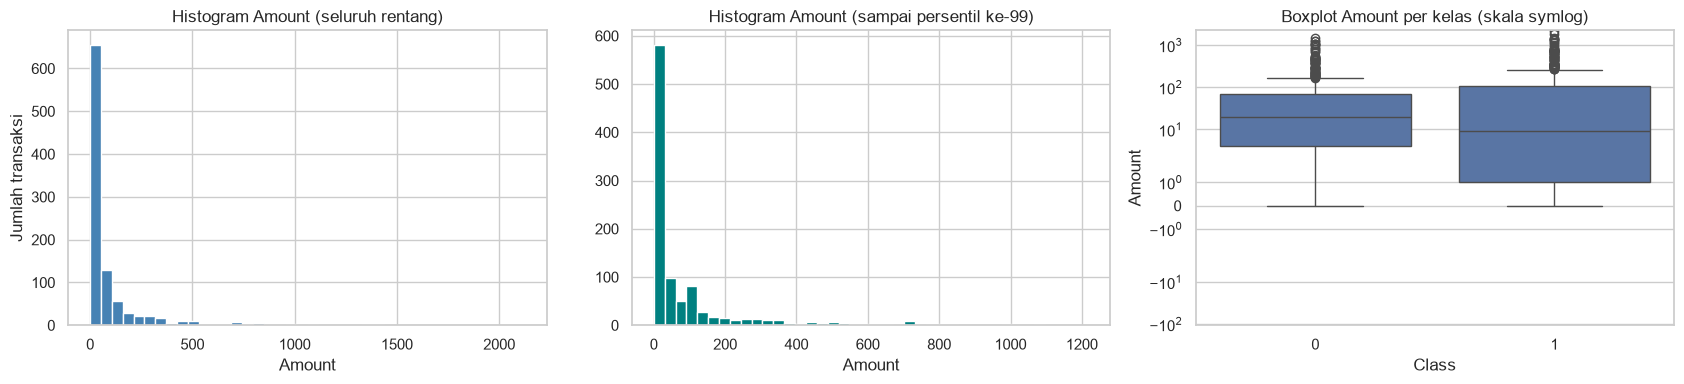

In [8]:
print(df.groupby("Class")["Amount"].describe().round(2))

p99 = df["Amount"].quantile(0.99)
print(f"\nPersentil ke-99 Amount: {p99:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

axes[0].hist(df["Amount"], bins=40, color="#4682B4")
axes[0].set_title("Histogram Amount (seluruh rentang)")
axes[0].set_xlabel("Amount"); axes[0].set_ylabel("Jumlah transaksi")

axes[1].hist(df.loc[df["Amount"] <= p99, "Amount"], bins=40, color="teal")
axes[1].set_title("Histogram Amount (sampai persentil ke-99)")
axes[1].set_xlabel("Amount")

sns.boxplot(data=df, x="Class", y="Amount", ax=axes[2])
axes[2].set_yscale("symlog")
axes[2].set_title("Boxplot Amount per kelas (skala symlog)")
plt.tight_layout()
plt.show()

Distribusi `Amount` berekor panjang ke kanan (rata-rata jauh di atas median) sehingga sensitif terhadap nilai ekstrem. Hal ini perlu diperhatikan pada tahap penskalaan.

## 3.4 Distribusi Waktu (`Time`)

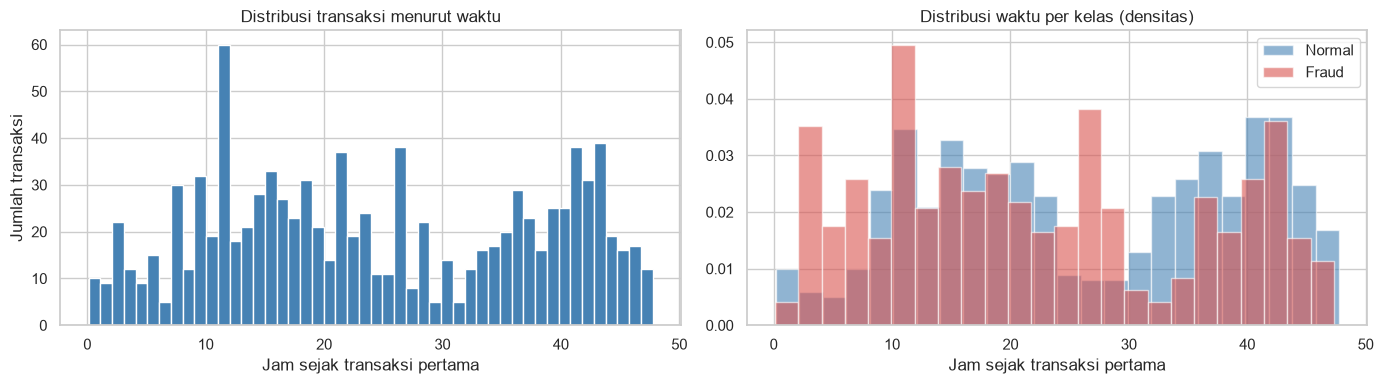

In [9]:
df_time = df.assign(Jam=df["Time"] / 3600)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(df_time["Jam"], bins=48, color="#4682B4")
axes[0].set_title("Distribusi transaksi menurut waktu")
axes[0].set_xlabel("Jam sejak transaksi pertama"); axes[0].set_ylabel("Jumlah transaksi")

for kelas, warna, label in [(0, "#4682B4", "Normal"), (1, "#D9534F", "Fraud")]:
    axes[1].hist(df_time.loc[df_time["Class"] == kelas, "Jam"], bins=24, alpha=0.6,
                 color=warna, label=label, density=True)
axes[1].set_title("Distribusi waktu per kelas (densitas)")
axes[1].set_xlabel("Jam sejak transaksi pertama"); axes[1].legend()
plt.tight_layout()
plt.show()

## 3.5 Korelasi Fitur dengan Target

Distribusi waktu kedua kelas saling tumpang tindih pada grafik. Time tetap ikut diuji dalam set fitur lengkap agar kontribusinya terhadap model dapat diamati.

10 fitur dengan korelasi absolut terbesar terhadap Class:
V14   -0.751
V4     0.713
V11    0.687
V12   -0.685
V10   -0.632
V16   -0.600
V3    -0.567
V17   -0.562
V9    -0.561
V2     0.495
Name: Class, dtype: float64


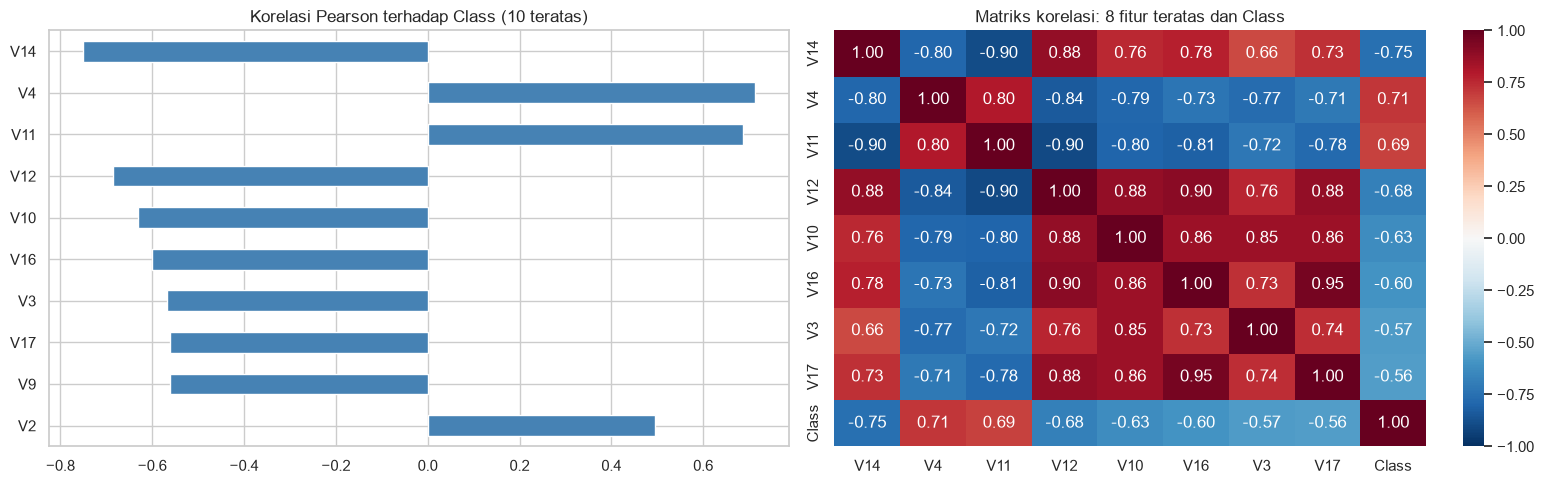

In [10]:
corr_target = df.corr()["Class"].drop("Class").sort_values(key=np.abs, ascending=False)
print("10 fitur dengan korelasi absolut terbesar terhadap Class:")
print(corr_target.head(10).round(3))

top_feats = corr_target.head(8).index.tolist()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
corr_target.head(10)[::-1].plot(kind="barh", ax=axes[0], color="#4682B4")
axes[0].set_title("Korelasi Pearson terhadap Class (10 teratas)")

sns.heatmap(df[top_feats + ["Class"]].corr(), annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Matriks korelasi: 8 fitur teratas dan Class")
plt.tight_layout()
plt.show()

Korelasi Pearson mengukur hubungan linear. Komposisi kelas dapat memengaruhi nilainya, sehingga korelasi pada subset ini perlu dibaca sesuai desain sampling. Pemilihan fitur pada bab 6 dihitung ulang dari data latih di dalam setiap fold validasi.

## 3.6 Perbandingan Distribusi Fitur Teratas per Kelas

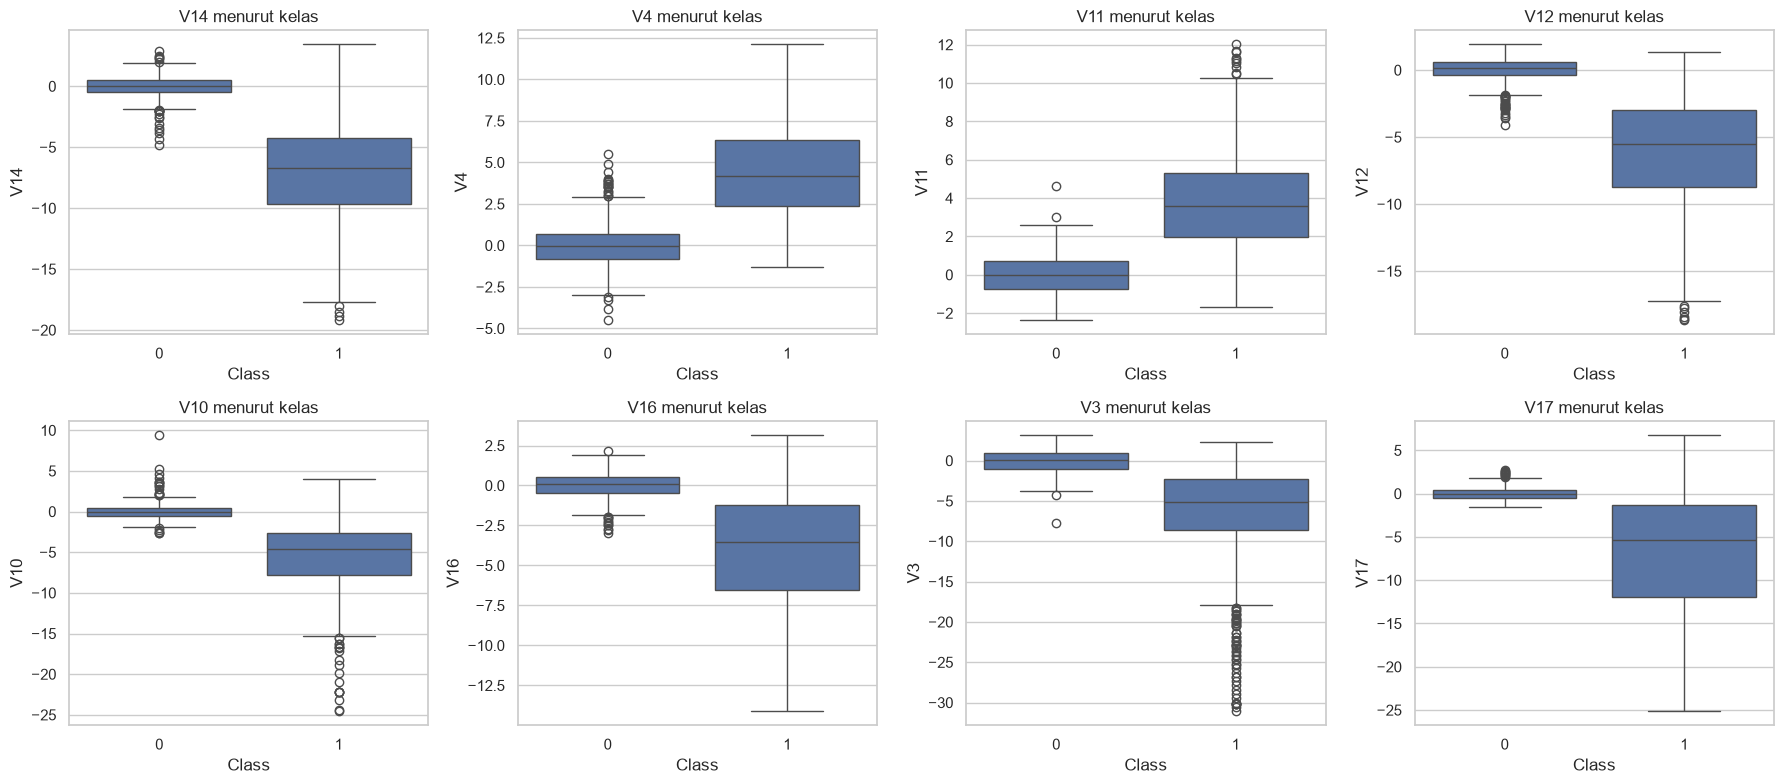

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, feat in zip(axes.ravel(), top_feats):
    sns.boxplot(data=df, x="Class", y=feat, ax=ax)
    ax.set_title(f"{feat} menurut kelas")
plt.tight_layout()
plt.show()

Pada subset ini, median V14, V12, dan V10 untuk fraud lebih rendah, sedangkan V4 dan V11 lebih tinggi. Pola tersebut menjadi kandidat untuk diuji pada data latih. Makna bisnis asli komponen PCA tetap tidak tersedia.

## 3.7 Pemeriksaan Kualitas Data (Missing Value dan Duplikat)

### Batas pembacaan angka sebelum dan sesudah cleaning

Seluruh tabel statistik per kelas dan korelasi Pearson pada bab 3 memakai subset awal 1.000 transaksi, sama dengan grafik EDA Progress 2. Jumlah outlier berubah ketika 19 duplikat dihapus pada bab 4. Kandidat outlier Amount adalah 116 pada data awal dan 113 pada data bersih. Jumlah Amount = 0 adalah 33 sebelum cleaning dan 31 sesudahnya. Dua hitungan ini memiliki penyebut dan tahap pemrosesan masing-masing.

In [12]:
# Tangani Data Kotor
print("\nMissing Values: ")
print(df.isnull().sum())

print(f"\nData Duplikat: {df.duplicated().sum()}")


Missing Values: 
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

Data Duplikat: 19


## 3.8 Pemeriksaan Kandidat Outlier (Metode IQR)

,Fitur,Jumlah outlier,Persentase (%),Batas bawah,Batas atas
0,V8,167,16.7,-1.856,2.482
1,V27,157,15.7,-0.837,1.226
2,V28,138,13.8,-0.456,0.608
3,V23,134,13.4,-0.886,0.840
4,V5,127,12.7,-5.083,3.840
5,V7,125,12.5,-8.004,5.265
6,V20,125,12.5,-1.163,1.437
7,Amount,116,11.6,-146.760,248.040
8,V21,110,11.0,-1.396,1.871
9,V18,102,10.2,-4.864,3.476


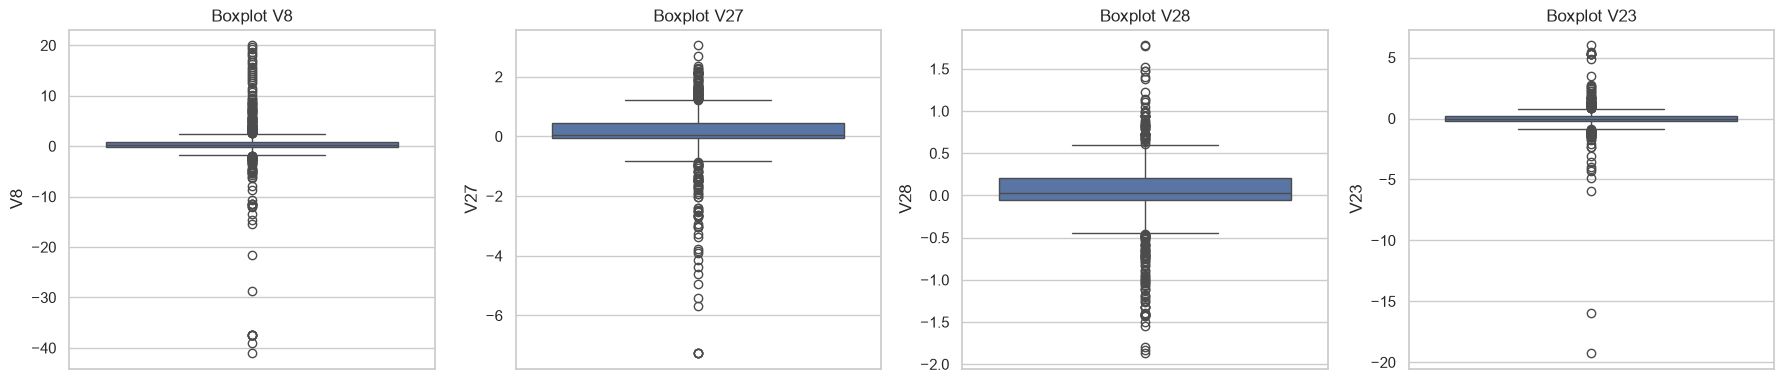

In [13]:
def hitung_outlier_iqr(data, kolom):
    q1, q3 = data[kolom].quantile([0.25, 0.75])
    iqr = q3 - q1
    batas_bawah, batas_atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (data[kolom] < batas_bawah) | (data[kolom] > batas_atas)
    return mask.sum(), batas_bawah, batas_atas

fitur = [c for c in df.columns if c != "Class"]
ringkas = []
for k in fitur:
    n, lo, hi = hitung_outlier_iqr(df, k)
    ringkas.append({"Fitur": k, "Jumlah outlier": n, "Persentase (%)": round(n / len(df) * 100, 2),
                    "Batas bawah": round(lo, 3), "Batas atas": round(hi, 3)})

tabel_outlier = pd.DataFrame(ringkas).sort_values("Jumlah outlier", ascending=False)
display(tabel_outlier.reset_index(drop=True))

top_out = tabel_outlier["Fitur"].head(4).tolist()
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, f in zip(axes, top_out):
    sns.boxplot(y=df[f], ax=ax)
    ax.set_title(f"Boxplot {f}")
plt.tight_layout()
plt.show()

# 4. Data Cleaning

Cleaning dilakukan pada salinan data (`df_clean`) agar data asli (`df`) tetap tersedia sebagai pembanding.

## 4.1 Penanganan Missing Value

In [14]:
df_clean = df.copy()
total_missing = int(df_clean.isna().sum().sum())
print(f"Total missing value: {total_missing}")
if total_missing:
    raise ValueError("Versi dataset ini seharusnya lengkap. Jika data berubah, rancang imputasi di dalam Pipeline data latih.")
print("Tidak diperlukan imputasi pada dataset kerja ini.")

Total missing value: 0
Tidak diperlukan imputasi pada dataset kerja ini.


## 4.2 Penanganan Data Duplikat

Karena tidak ada ID transaksi, baris yang identik pada seluruh kolom tidak pasti merupakan kesalahan pencatatan. Namun baris identik yang tersebar di data latih dan data uji menimbulkan **kebocoran data (*data leakage*)** dan membuat performa model tampak lebih baik dari seharusnya. Karena itu duplikat diperiksa dulu, lalu dihapus (menyisakan kemunculan pertama).

In [15]:
mask_dup_semua = df_clean.duplicated(keep=False)   # semua salinan, termasuk yang pertama
mask_dup_lebih = df_clean.duplicated(keep="first") # hanya salinan kelebihan

print(f"Baris yang punya kembaran (semua salinan): {mask_dup_semua.sum()}")
print(f"Baris duplikat kelebihan yang akan dihapus: {mask_dup_lebih.sum()}")
print("\nDistribusi kelas pada baris duplikat kelebihan:")
print(df_clean.loc[mask_dup_lebih, "Class"].value_counts())

print("\nContoh baris duplikat:")
display(df_clean[mask_dup_semua].sort_values(["Time", "Amount"]).head(8))

Baris yang punya kembaran (semua salinan): 32
Baris duplikat kelebihan yang akan dihapus: 19

Distribusi kelas pada baris duplikat kelebihan:
Class
1    19
Name: count, dtype: int64

Contoh baris duplikat:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
410,68207.0,-13.192671,12.785971,-9.906650,3.320337,-4.801176,5.760059,-18.750889,-37.353443,-0.391540,-5.052502,4.406806,-4.610756,-1.909488,-9.072711,-0.226074,-6.211557,-6.248145,-3.149247,0.051576,-3.493050,27.202839,-8.887017,5.303607,-0.639435,0.263203,-0.108877,1.269566,0.939407,1.0,1
411,68207.0,-13.192671,12.785971,-9.906650,3.320337,-4.801176,5.760059,-18.750889,-37.353443,-0.391540,-5.052502,4.406806,-4.610756,-1.909488,-9.072711,-0.226074,-6.211557,-6.248145,-3.149247,0.051576,-3.493050,27.202839,-8.887017,5.303607,-0.639435,0.263203,-0.108877,1.269566,0.939407,1.0,1
412,68207.0,-13.192671,12.785971,-9.906650,3.320337,-4.801176,5.760059,-18.750889,-37.353443,-0.391540,-5.052502,4.406806,-4.610756,-1.909488,-9.072711,-0.226074,-6.211557,-6.248145,-3.149247,0.051576,-3.493050,27.202839,-8.887017,5.303607,-0.639435,0.263203,-0.108877,1.269566,0.939407,1.0,1
413,68207.0,-13.192671,12.785971,-9.906650,3.320337,-4.801176,5.760059,-18.750889,-37.353443,-0.391540,-5.052502,4.406806,-4.610756,-1.909488,-9.072711,-0.226074,-6.211557,-6.248145,-3.149247,0.051576,-3.493050,27.202839,-8.887017,5.303607,-0.639435,0.263203,-0.108877,1.269566,0.939407,1.0,1
414,68207.0,-13.192671,12.785971,-9.906650,3.320337,-4.801176,5.760059,-18.750889,-37.353443,-0.391540,-5.052502,4.406806,-4.610756,-1.909488,-9.072711,-0.226074,-6.211557,-6.248145,-3.149247,0.051576,-3.493050,27.202839,-8.887017,5.303607,-0.639435,0.263203,-0.108877,1.269566,0.939407,1.0,1
415,68207.0,-13.192671,12.785971,-9.906650,3.320337,-4.801176,5.760059,-18.750889,-37.353443,-0.391540,-5.052502,4.406806,-4.610756,-1.909488,-9.072711,-0.226074,-6.211557,-6.248145,-3.149247,0.051576,-3.493050,27.202839,-8.887017,5.303607,-0.639435,0.263203,-0.108877,1.269566,0.939407,1.0,1
512,84204.0,-0.937843,3.462889,-6.445104,4.932199,-2.233983,-2.291561,-5.695594,1.338825,-4.322377,-8.099119,7.182967,-9.445943,-0.314620,-12.991466,-0.136359,-6.367524,-12.734394,-3.845130,1.007667,1.129532,1.066550,-0.521657,-0.319917,-0.405859,0.906802,1.165784,1.374495,0.729889,0.0,1
513,84204.0,-0.937843,3.462889,-6.445104,4.932199,-2.233983,-2.291561,-5.695594,1.338825,-4.322377,-8.099119,7.182967,-9.445943,-0.314620,-12.991466,-0.136359,-6.367524,-12.734394,-3.845130,1.007667,1.129532,1.066550,-0.521657,-0.319917,-0.405859,0.906802,1.165784,1.374495,0.729889,0.0,1


In [16]:
sebelum = len(df_clean)
df_clean = df_clean.drop_duplicates(keep="first").reset_index(drop=True)
print(f"Jumlah baris sebelum : {sebelum}")
print(f"Jumlah baris sesudah : {len(df_clean)}")
print(f"Duplikat tersisa     : {df_clean.duplicated().sum()}")
print("\nDistribusi kelas setelah penghapusan duplikat:")
print(df_clean["Class"].value_counts().sort_index())

Jumlah baris sebelum : 1000
Jumlah baris sesudah : 981
Duplikat tersisa     : 0

Distribusi kelas setelah penghapusan duplikat:
Class
0    508
1    473
Name: count, dtype: int64


Seluruh duplikat berada pada kelas fraud, sehingga penghapusan duplikat mengurangi jumlah sampel fraud, sedangkan jumlah transaksi normal tidak berubah.

## 4.3 Penanganan Outlier

Kandidat outlier dipertahankan karena dapat memuat informasi fraud. RobustScaler dipakai untuk Amount pada Pipeline SVM. Transformasi skala mempertahankan observasi ekstrem dan mengubah ukuran numeriknya. Random Forest menggunakan nilai numerik asli.

In [17]:
# Periksa sebaran kandidat outlier Amount menurut kelas
n_out, lo, hi = hitung_outlier_iqr(df_clean, "Amount")
mask_out_amount = (df_clean["Amount"] < lo) | (df_clean["Amount"] > hi)
print(f"Batas IQR Amount: [{lo:.2f}, {hi:.2f}]")
print(f"Kandidat outlier Amount: {n_out} ({n_out / len(df_clean) * 100:.2f}%)")
print("\nKelas pada kandidat outlier Amount:")
print(df_clean.loc[mask_out_amount, "Class"].value_counts())

# Transaksi bernilai nol
n_nol = (df_clean["Amount"] == 0).sum()
print(f"\nTransaksi dengan Amount = 0: {n_nol}")
print(df_clean.loc[df_clean["Amount"] == 0, "Class"].value_counts().rename("Jumlah per kelas"))

Batas IQR Amount: [-146.76, 248.04]
Kandidat outlier Amount: 113 (11.52%)

Kelas pada kandidat outlier Amount:
Class
1    71
0    42
Name: count, dtype: int64

Transaksi dengan Amount = 0: 31
Class
1    25
0     6
Name: Jumlah per kelas, dtype: int64


Sebanyak 31 transaksi dengan Amount = 0 dipertahankan karena data sumber tidak menyediakan bukti bahwa nilainya salah. Jenis transaksi yang menyebabkan nominal nol tidak tersedia.

## 4.4 Validasi Hasil Cleaning

In [18]:
def audit_cleaning(frame):
    _, low, high = hitung_outlier_iqr(frame, "Amount")
    return {
        "Jumlah baris": len(frame),
        "Normal": int(frame["Class"].eq(0).sum()),
        "Fraud": int(frame["Class"].eq(1).sum()),
        "Missing value": int(frame.isna().sum().sum()),
        "Duplikat berlebih": int(frame.duplicated().sum()),
        "Kandidat outlier Amount": int(((frame["Amount"] < low) | (frame["Amount"] > high)).sum()),
        "Amount = 0": int(frame["Amount"].eq(0).sum()),
    }

display(pd.DataFrame({"Sebelum": audit_cleaning(df), "Sesudah": audit_cleaning(df_clean)}))

,Sebelum,Sesudah
Jumlah baris,1000,981
Normal,508,508
Fraud,492,473
Missing value,0,0
Duplikat berlebih,19,0
Kandidat outlier Amount,116,113
Amount = 0,33,31


# 5. Preprocessing

Urutan langkah dibuat agar bebas kebocoran data: **pisahkan data latih dan uji dahulu, baru lakukan penskalaan** dengan parameter yang dipelajari hanya dari data latih.

## 5.1 Pemisahan Fitur dan Target

### Hubungan preprocessing Progress 2 dengan pemodelan saat ini

Progress 2 menampilkan rancangan awal Amount memakai RobustScaler, Time memakai StandardScaler, dan V1-V28 dipertahankan. Pada notebook akhir, kebutuhan scaling ditentukan oleh model. SVM memakai RobustScaler untuk Amount serta StandardScaler untuk Time dan V1-V28 di dalam Pipeline. Random Forest memakai angka pada skala asal. Komponen PCA dapat memiliki varians yang berbeda.

Rasio data bersih sekitar 51,78% normal dan 48,22% fraud. Eksperimen pada subset ini menggunakan class_weight=None dan tanpa resampling tambahan. Aturan minoritas kurang dari 30% pada slide memerlukan eksperimen tersendiri sebelum diterapkan pada data lain.

In [19]:
X = df_clean.drop(columns=["Class"])
y = df_clean["Class"]
print("Bentuk X:", X.shape, "| Bentuk y:", y.shape)

Bentuk X: (981, 30) | Bentuk y: (981,)


## 5.2 Pembagian Data Latih dan Uji (Stratified)

Pembagian 80:20 dengan `stratify=y` agar proporsi fraud pada data latih dan uji sama dengan data keseluruhan.

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print(f"Data latih: {X_train.shape[0]} baris | Data uji: {X_test.shape[0]} baris\n")
dist = pd.DataFrame({
    "Seluruh data": y.value_counts(normalize=True).sort_index() * 100,
    "Latih": y_train.value_counts(normalize=True).sort_index() * 100,
    "Uji": y_test.value_counts(normalize=True).sort_index() * 100,
}).round(2)
dist.index = ["Normal (0) %", "Fraud (1) %"]
display(dist)

Data latih: 784 baris | Data uji: 197 baris



,Seluruh data,Latih,Uji
Normal (0) %,51.78,51.79,51.78
Fraud (1) %,48.22,48.21,48.22


## 5.3 Pipeline preprocessing dan penanganan kelas

SVM sensitif terhadap skala fitur. Gunakan RobustScaler untuk Amount serta StandardScaler untuk Time dan komponen V1-V28. PCA dapat menghasilkan komponen dengan varians berbeda. Random Forest memproses 30 fitur pada skala aslinya.

Pipeline menghitung parameter transformasi dari bagian latih setiap fold. Proporsi kelas data bersih sekitar 52% normal dan 48% fraud, sehingga eksperimen ini memakai class_weight=None dan tanpa resampling tambahan. Keputusan tersebut berlaku pada subset kerja ini.

Rujukan praktikum adalah Modul 6 (SVM), halaman 8-11, dan Modul 7 (Random Forest), halaman 2-5. Sel berikut mendefinisikan preprocessing untuk dipelajari bersama model saat fit.

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

kolom_standard = [column for column in X_train if column != "Amount"]
preprocessor_svm = ColumnTransformer([
    ("amount", RobustScaler(), ["Amount"]),
    ("standard", StandardScaler(), kolom_standard),
])
display(pd.DataFrame({
    "Bagian": ["Amount pada SVM", "Time dan V1-V28 pada SVM", "Seluruh fitur pada Random Forest"],
    "Perlakuan": ["RobustScaler", "StandardScaler", "Nilai numerik asli"],
}))

,Bagian,Perlakuan
0,Amount pada SVM,RobustScaler
1,Time dan V1-V28 pada SVM,StandardScaler
2,Seluruh fitur pada Random Forest,Nilai numerik asli


## 5.4 Verifikasi pembagian data

Bandingkan indeks dan isi baris kedua bagian untuk memastikan pemisahannya. Seluruh 30 fitur dipisahkan dari Class sebelum pelatihan. Data uji baru dipakai untuk prediksi pada bab evaluasi.

In [22]:
assert "Class" not in X_train.columns
assert X_train.index.intersection(X_test.index).empty
assert not pd.concat([X_train, X_test]).duplicated().any()
assert np.isfinite(X_train.to_numpy()).all() and np.isfinite(X_test.to_numpy()).all()
print(f"Pembagian terverifikasi: {len(X_train)} latih dan {len(X_test)} uji, masing-masing {X_train.shape[1]} fitur.")

Pembagian terverifikasi: 784 latih dan 197 uji, masing-masing 30 fitur.


# 6. Seleksi Fitur

Uji tiga alternatif fitur sebelum membandingkan SVM dan Random Forest. Mulai dengan 10 fitur berkorelasi absolut tertinggi terhadap Class. Untuk kandidat dengan korelasi antarfitur absolut minimal 0,95, pertahankan fitur yang hubungannya dengan Class lebih kuat. Top 10 dan ambang 0,95 adalah aturan eksperimen.

Definisi seleksi serta hasil perbandingan berasal dari notebook 02_feature_selection.ipynb. Semua pemeringkatan dalam validasi silang dihitung ulang hanya menggunakan bagian latih fold. Tabel dan heatmap memakai seluruh data latih untuk menyajikan keputusan kandidat.

In [23]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import auc, precision_recall_curve, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold

X_latih_fs, X_uji_fs = X_train, X_test
y_latih_fs, y_uji_fs = y_train, y_test
seed_fs = RANDOM_STATE

In [24]:
def seleksi_fitur(fitur, label, jumlah_kandidat=10, ambang=0.95):
    korelasi = fitur.corrwith(label, method="pearson")
    korelasi = korelasi.sort_values(key=lambda nilai: nilai.abs(), ascending=False, kind="stable")
    kandidat = korelasi.head(jumlah_kandidat).index.tolist()
    antarfitur = fitur[kandidat].corr(method="pearson")

    terpilih, pasangan = [], {}
    for nama in kandidat:
        mirip = next(
            (pilihan for pilihan in terpilih if abs(antarfitur.loc[nama, pilihan]) >= ambang),
            None,
        )
        if mirip is None:
            terpilih.append(nama)
        else:
            pasangan[nama] = (mirip, antarfitur.loc[nama, mirip])
    return korelasi, kandidat, terpilih, pasangan


korelasi_fs, kandidat_fs, fitur_terpilih_fs, pasangan_fs = seleksi_fitur(X_latih_fs, y_latih_fs)
baris_fs = []
for peringkat, (nama, nilai) in enumerate(korelasi_fs.items(), start=1):
    if nama in fitur_terpilih_fs:
        keputusan = "Dipertahankan"
        alasan = "Masuk 10 besar dan lolos ambang korelasi antarfitur."
    elif nama in pasangan_fs:
        pasangan, nilai_pasangan = pasangan_fs[nama]
        keputusan = "Dikeluarkan"
        alasan = f"Korelasi dengan {pasangan} {nilai_pasangan:+.3f}. {pasangan} lebih kuat terhadap Class."
    else:
        keputusan = "Di luar kandidat"
        alasan = "Korelasi absolut dengan Class berada di luar 10 besar."
    baris_fs.append({
        "Peringkat": peringkat, "Fitur": nama, "Korelasi dengan Class": nilai,
        "|Korelasi|": abs(nilai), "Keputusan": keputusan, "Alasan": alasan,
    })

tabel_fitur_fs = pd.DataFrame(baris_fs).set_index("Peringkat").round(3)
display(tabel_fitur_fs)

,Fitur,Korelasi dengan Class,|Korelasi|,Keputusan,Alasan
Peringkat,,,,,
1,V14,-0.755,0.755,Dipertahankan,Masuk 10 besar dan lolos ambang korelasi antarfitur.
2,V4,0.717,0.717,Dipertahankan,Masuk 10 besar dan lolos ambang korelasi antarfitur.
3,V12,-0.693,0.693,Dipertahankan,Masuk 10 besar dan lolos ambang korelasi antarfitur.
4,V11,0.691,0.691,Dipertahankan,Masuk 10 besar dan lolos ambang korelasi antarfitur.
5,V10,-0.636,0.636,Dipertahankan,Masuk 10 besar dan lolos ambang korelasi antarfitur.
6,V16,-0.592,0.592,Dipertahankan,Masuk 10 besar dan lolos ambang korelasi antarfitur.
7,V3,-0.571,0.571,Dipertahankan,Masuk 10 besar dan lolos ambang korelasi antarfitur.
8,V9,-0.564,0.564,Dipertahankan,Masuk 10 besar dan lolos ambang korelasi antarfitur.
9,V17,-0.555,0.555,Dikeluarkan,Korelasi dengan V16 +0.955. V16 lebih kuat terhadap Class.


## 6.1 Tampilkan matriks korelasi

Heatmap menampilkan fitur terpilih, kandidat yang dikeluarkan karena sangat berkorelasi, serta *Time* dan *Amount*. Baca kolom *Class* untuk melihat hubungan tiap fitur dengan label fraud.

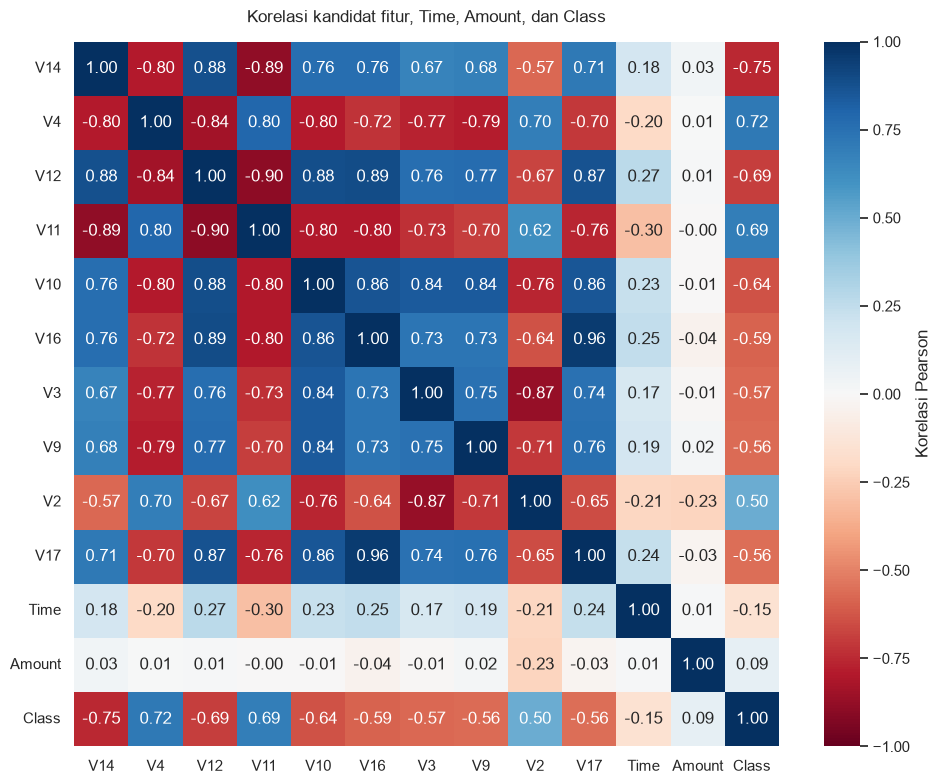

In [25]:
kolom_matriks_fs = list(dict.fromkeys(fitur_terpilih_fs + list(pasangan_fs) + ["Time", "Amount"]))
matriks_fs = X_latih_fs[kolom_matriks_fs].assign(Class=y_latih_fs).corr(method="pearson")

fig_fs, ax_fs = plt.subplots(figsize=(10, 8))
sns.heatmap(
    matriks_fs, annot=True, fmt=".2f", cmap="RdBu", center=0,
    vmin=-1, vmax=1, square=True, ax=ax_fs,
    cbar_kws={"label": "Korelasi Pearson"},
)
ax_fs.set_title("Korelasi kandidat fitur, Time, Amount, dan Class", pad=14)
ax_fs.tick_params(axis="both", labelrotation=0)
fig_fs.tight_layout()
plt.show()

## 6.2 Bandingkan hasil validasi

Gunakan lima fold terstratifikasi yang sama untuk tiap set fitur. Pada setiap fold, pemilihan fitur dihitung ulang dari bagian latih agar data validasi tidak memengaruhi pilihan. PR-AUC dihitung sebagai luas trapesium di bawah kurva precision–recall. Precision dan recall memakai prediksi kelas bawaan Random Forest.

In [26]:
cv_fs = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed_fs)
hasil_fs = []

for fold, (indeks_fit, indeks_validasi) in enumerate(cv_fs.split(X_latih_fs, y_latih_fs), start=1):
    X_fit, X_val = X_latih_fs.iloc[indeks_fit], X_latih_fs.iloc[indeks_validasi]
    y_fit, y_val = y_latih_fs.iloc[indeks_fit], y_latih_fs.iloc[indeks_validasi]
    _, kandidat_fold, terpilih_fold, _ = seleksi_fitur(X_fit, y_fit)

    set_fitur = {
        "Fitur lengkap": X_fit.columns.tolist(),
        "10 kandidat": kandidat_fold,
        "Set ringkas": terpilih_fold,
    }
    for nama_set, kolom in set_fitur.items():
        model = RandomForestClassifier(n_estimators=300, random_state=seed_fs, n_jobs=1)
        model.fit(X_fit[kolom], y_fit)
        skor = model.predict_proba(X_val[kolom])[:, 1]
        prediksi = model.predict(X_val[kolom])
        precision_curve, recall_curve, _ = precision_recall_curve(y_val, skor)
        hasil_fs.append({
            "Fold": fold, "Set fitur": nama_set, "Jumlah fitur": len(kolom),
            "PR-AUC": auc(recall_curve, precision_curve),
            "Precision": precision_score(y_val, prediksi, zero_division=0),
            "Recall": recall_score(y_val, prediksi, zero_division=0),
        })

hasil_cv_fs = pd.DataFrame(hasil_fs)
ringkasan_cv_fs = hasil_cv_fs.groupby("Set fitur", sort=False).agg(
    **{
        "Jumlah fitur rata-rata": ("Jumlah fitur", "mean"),
        "PR-AUC rata-rata": ("PR-AUC", "mean"),
        "Simpangan baku PR-AUC": ("PR-AUC", "std"),
        "Precision rata-rata": ("Precision", "mean"),
        "Recall rata-rata": ("Recall", "mean"),
    }
)
display(ringkasan_cv_fs.round(4))
display(hasil_cv_fs.pivot(index="Fold", columns="Set fitur", values="PR-AUC").round(4))

,Jumlah fitur rata-rata,PR-AUC rata-rata,Simpangan baku PR-AUC,Precision rata-rata,Recall rata-rata
Set fitur,,,,,
Fitur lengkap,30.0,0.9822,0.0063,0.9802,0.8944
10 kandidat,10.0,0.9804,0.0068,0.9603,0.8917
Set ringkas,9.0,0.9798,0.0083,0.9608,0.8996


Set fitur,10 kandidat,Fitur lengkap,Set ringkas
Fold,,,
1,0.9872,0.9851,0.9868
2,0.9695,0.9730,0.9662
3,0.9825,0.9869,0.9836
4,0.9839,0.9875,0.9847
5,0.9789,0.9787,0.9775


## 6.3 Catat hasil seleksi

Korelasi dipakai untuk menyusun kandidat. Hasil validasi mengukur dampak pengurangan fitur terhadap Random Forest. *Time* dan *Amount* tetap ikut diuji dalam set lengkap.

In [27]:
skor_lengkap_fs = ringkasan_cv_fs.loc["Fitur lengkap", "PR-AUC rata-rata"]
skor_ringkas_fs = ringkasan_cv_fs.loc["Set ringkas", "PR-AUC rata-rata"]
selisih_fs = 100 * (skor_lengkap_fs - skor_ringkas_fs)
dikeluarkan_fs = [nama for nama in X_latih_fs if nama not in fitur_terpilih_fs]

ringkasan_fs = [
    f"**Dipertahankan ({len(fitur_terpilih_fs)} fitur).** " + ", ".join(fitur_terpilih_fs) + ".",
    "**Dikeluarkan dari set ringkas.** " + ", ".join(dikeluarkan_fs) + ".",
    f"**Hasil validasi.** PR-AUC set lengkap {skor_lengkap_fs:.4f}, set ringkas {skor_ringkas_fs:.4f}. "
    f"Selisih set lengkap dikurangi set ringkas sebesar {selisih_fs:+.2f} poin persentase.",
]
display(Markdown("\n\n".join(ringkasan_fs)))

**Dipertahankan (9 fitur).** V14, V4, V12, V11, V10, V16, V3, V9, V2.

**Dikeluarkan dari set ringkas.** Time, V1, V5, V6, V7, V8, V13, V15, V17, V18, V19, V20, V21, V22, V23, V24, V25, V26, V27, V28, Amount.

**Hasil validasi.** PR-AUC set lengkap 0.9822, set ringkas 0.9798. Selisih set lengkap dikurangi set ringkas sebesar +0.25 poin persentase.

**Keputusan untuk tahap pemodelan.** Tim mempertahankan 30 fitur sesuai prioritas skor PR-AUC validasi pada percobaan ini. Set 9 fitur merupakan alternatif yang lebih ringkas dan tetap didokumentasikan. Pemodelan SVM dan Random Forest berikut memakai 30 kolom input yang sama. Class tetap menjadi target.

# 7. Modeling

## 7.1 Model dan ukuran pembanding

SVM linear mengikuti Modul 6 dengan C=1 sebagai konfigurasi awal. SVM mencari batas pemisah antar kelas setelah scaling. Random Forest mengikuti Modul 7 dengan 100 pohon dan kedalaman maksimum 5. Pembatasan kedalaman mengendalikan kompleksitas setiap pohon. DummyClassifier memberikan acuan sederhana yang menghasilkan skor konstan berdasarkan proporsi kelas latih.

PR-AUC di notebook ini dihitung dengan integrasi trapesium kurva precision-recall. Average Precision (AP) ikut dicatat sebagai ukuran terpisah. Untuk skor prediksi konstan, AP sama dengan proporsi kelas positif, sedangkan PR-AUC trapesium lebih tinggi karena interpolasi antar titik kurva. Gunakan definisi yang sama saat membandingkan setiap model. SVM menyediakan decision_function dan Random Forest menyediakan predict_proba untuk menghitung kurva. Skor SVM pada bagian ini berupa jarak keputusan. Modul tidak mewajibkan lima fold atau GridSearchCV; keduanya digunakan untuk membandingkan konfigurasi pada pembagian yang sama.

In [28]:
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.metrics import make_scorer
from sklearn.model_selection import cross_validate, GridSearchCV
from sklearn.svm import SVC

def hitung_pr_auc(y_true, scores):
    precision, recall, _ = precision_recall_curve(y_true, scores)
    return auc(recall, precision)

scorer_pr_auc = make_scorer(
    hitung_pr_auc, response_method=("decision_function", "predict_proba")
)
scoring = {
    "pr_auc": scorer_pr_auc,
    "ap": "average_precision",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": "f1",
}
fold_model = list(StratifiedKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE
).split(X_train, y_train))

model_awal = {
    "Baseline konstan": DummyClassifier(strategy="prior"),
    "SVM linear": Pipeline([
        ("preprocessing", clone(preprocessor_svm)),
        ("svm", SVC(kernel="linear", C=1.0, random_state=RANDOM_STATE)),
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=5, criterion="gini", random_state=RANDOM_STATE, n_jobs=1
    ),
}
hasil_awal = []
for nama, estimator in model_awal.items():
    scores = cross_validate(estimator, X_train, y_train, cv=fold_model, scoring=scoring, n_jobs=1)
    hasil_awal.append({
        "Model": nama, "PR-AUC CV": scores["test_pr_auc"].mean(),
        "SD PR-AUC": scores["test_pr_auc"].std(ddof=1),
        "AP CV": scores["test_ap"].mean(), "Precision CV": scores["test_precision"].mean(),
        "Recall CV": scores["test_recall"].mean(), "F1 CV": scores["test_f1"].mean(),
    })
tabel_awal = pd.DataFrame(hasil_awal).set_index("Model")
display(tabel_awal.round(4))

,PR-AUC CV,SD PR-AUC,AP CV,Precision CV,Recall CV,F1 CV
Model,,,,,,
Baseline konstan,0.7411,0.0014,0.4821,0.0000,0.0000,0.0000
SVM linear,0.9832,0.0083,0.9832,0.9746,0.8969,0.9338
Random Forest,0.9822,0.0062,0.9823,0.9855,0.8838,0.9311


In [29]:
nama_awal = tabel_awal["PR-AUC CV"].idxmax()
display(Markdown(
    f"Pada konfigurasi awal, **{nama_awal}** memperoleh rata-rata PR-AUC CV tertinggi, "
    f"yaitu **{tabel_awal.loc[nama_awal, 'PR-AUC CV']:.4f}**. "
    "Baris baseline memperlihatkan hasil saat model belum memanfaatkan variasi fitur. "
    "Precision, recall, dan F1 menguraikan hasil prediksi pada ambang bawaan masing-masing model."
))

Pada konfigurasi awal, **SVM linear** memperoleh rata-rata PR-AUC CV tertinggi, yaitu **0.9832**. Baris baseline memperlihatkan hasil saat model belum memanfaatkan variasi fitur. Precision, recall, dan F1 menguraikan hasil prediksi pada ambang bawaan masing-masing model.

## 7.2 Pencarian parameter pada data latih

Uji C SVM sebesar 0,1; 1; dan 10 untuk mengatur regularisasi. Untuk Random Forest, uji 100 atau 300 pohon dan kedalaman maksimum 5 atau tanpa batas eksplisit. Kombinasi jumlah pohon dan kedalaman dipilih dari rata-rata PR-AUC pada lima fold yang sama. Nilai SD menunjukkan variasi antar-fold; selisih kecil perlu dibaca bersama variasinya. Skor terbaik hasil pencarian bisa optimistis karena dipakai memilih konfigurasi, sehingga hasil uji tetap dilaporkan terpisah.

In [30]:
ruang_parameter = {
    "SVM linear": {"svm__C": [0.1, 1.0, 10.0]},
    "Random Forest": {"n_estimators": [100, 300], "max_depth": [5, None]},
}
pencarian = {}
hasil_parameter = []
for nama, parameter in ruang_parameter.items():
    search = GridSearchCV(
        model_awal[nama], parameter, scoring=scoring, refit="pr_auc",
        cv=fold_model, n_jobs=1, error_score="raise", return_train_score=True,
    )
    search.fit(X_train, y_train)
    pencarian[nama] = search
    record = pd.DataFrame(search.cv_results_)[[
        "params", "mean_test_pr_auc", "std_test_pr_auc", "mean_train_pr_auc", "mean_test_recall"
    ]].copy()
    record.insert(0, "Model", nama)
    hasil_parameter.append(record)

tabel_parameter = pd.concat(hasil_parameter, ignore_index=True)
display(tabel_parameter.round(4))
perbandingan_cv = pd.DataFrame([
    {"Model": nama, "PR-AUC CV terbaik": hasil.best_score_,
     "SD PR-AUC CV": hasil.cv_results_["std_test_pr_auc"][hasil.best_index_],
     "Parameter": hasil.best_params_}
    for nama, hasil in pencarian.items()
]).set_index("Model")
display(perbandingan_cv.round(4))
nama_terpilih = perbandingan_cv["PR-AUC CV terbaik"].idxmax()
model_terpilih = pencarian[nama_terpilih].best_estimator_
display(Markdown(
    f"**Pilihan sebelum membuka hasil uji adalah {nama_terpilih}**, "
    f"dengan parameter {pencarian[nama_terpilih].best_params_}. "
    "Keputusan ditentukan menggunakan skor validasi data latih. Selisih rata-rata harus dibaca "
    "bersama simpangan baku antar-fold dan ukuran sampel yang kecil; ranking ini merupakan hasil eksperimen pada subset."
))

,Model,params,mean_test_pr_auc,std_test_pr_auc,mean_train_pr_auc,mean_test_recall
0,SVM linear,{'svm__C': 0.1},0.9849,0.0058,0.9894,0.8863
1,SVM linear,{'svm__C': 1.0},0.9832,0.0074,0.9903,0.8969
2,SVM linear,{'svm__C': 10.0},0.9836,0.0074,0.9911,0.9181
3,Random Forest,"{'max_depth': 5, 'n_estimators': 100}",0.9822,0.0055,0.9969,0.8838
4,Random Forest,"{'max_depth': 5, 'n_estimators': 300}",0.9820,0.0058,0.9972,0.8811
5,Random Forest,"{'max_depth': None, 'n_estimators': 100}",0.9818,0.0054,1.0000,0.8996
6,Random Forest,"{'max_depth': None, 'n_estimators': 300}",0.9822,0.0056,1.0000,0.8944


,PR-AUC CV terbaik,SD PR-AUC CV,Parameter
Model,,,
SVM linear,0.9849,0.0058,{'svm__C': 0.1}
Random Forest,0.9822,0.0056,"{'max_depth': None, 'n_estimators': 300}"


**Pilihan sebelum membuka hasil uji adalah SVM linear**, dengan parameter {'svm__C': 0.1}. Keputusan ditentukan menggunakan skor validasi data latih. Selisih rata-rata harus dibaca bersama simpangan baku antar-fold dan ukuran sampel yang kecil; ranking ini merupakan hasil eksperimen pada subset.

# 8. Evaluasi

## 8.1 Pengujian model yang sudah ditetapkan

Prediksi 197 transaksi uji memakai dua konfigurasi terpilih dan baseline. Tabel membandingkan hasil uji tanpa pencarian parameter tambahan. Pilihan model tetap mengikuti bab 7. Skor fraud merujuk Class=1. TN adalah normal terdeteksi normal, FP adalah normal diberi alarm fraud, FN adalah fraud terlewat, dan TP adalah fraud terdeteksi.

PR-AUC dan AP merangkum kualitas pemeringkatan pada berbagai ambang keputusan. Precision, recall, F1, dan confusion matrix memakai ambang bawaan model. PR-AUC yang tinggi perlu dibaca bersama komposisi sampel uji yang hampir seimbang.

In [31]:
from sklearn.metrics import (
    average_precision_score, accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, f1_score,
)

model_uji = {"Baseline konstan": clone(model_awal["Baseline konstan"]).fit(X_train, y_train)}
model_uji.update({nama: hasil.best_estimator_ for nama, hasil in pencarian.items()})
prediksi_uji, skor_uji, hasil_uji = {}, {}, []
for nama, estimator in model_uji.items():
    prediksi = estimator.predict(X_test)
    skor = (estimator.decision_function(X_test) if hasattr(estimator, "decision_function")
            else estimator.predict_proba(X_test)[:, 1])
    prediksi_uji[nama], skor_uji[nama] = prediksi, skor
    tn, fp, fn, tp = confusion_matrix(y_test, prediksi, labels=[0, 1]).ravel()
    hasil_uji.append({
        "Model": nama, "PR-AUC": hitung_pr_auc(y_test, skor),
        "AP": average_precision_score(y_test, skor),
        "Precision fraud": precision_score(y_test, prediksi, zero_division=0),
        "Recall fraud": recall_score(y_test, prediksi, zero_division=0),
        "F1 fraud": f1_score(y_test, prediksi, zero_division=0),
        "Accuracy": accuracy_score(y_test, prediksi), "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    })
tabel_uji = pd.DataFrame(hasil_uji).set_index("Model")
display(tabel_uji.round(4))
print(f"Classification report model pilihan: {nama_terpilih}")
print(classification_report(
    y_test, prediksi_uji[nama_terpilih], labels=[0, 1],
    target_names=["Normal", "Fraud"], zero_division=0,
))

,PR-AUC,AP,Precision fraud,Recall fraud,F1 fraud,Accuracy,TN,FP,FN,TP
Model,,,,,,,,,,
Baseline konstan,0.7411,0.4822,0.0000,0.0000,0.0000,0.5178,102,0,95,0
SVM linear,0.9813,0.9814,0.9880,0.8632,0.9213,0.9289,101,1,13,82
Random Forest,0.9852,0.9853,0.9767,0.8842,0.9282,0.9340,100,2,11,84


Classification report model pilihan: SVM linear
              precision    recall  f1-score   support

      Normal       0.89      0.99      0.94       102
       Fraud       0.99      0.86      0.92        95

    accuracy                           0.93       197
   macro avg       0.94      0.93      0.93       197
weighted avg       0.94      0.93      0.93       197



## 8.2 Confusion matrix dan kurva precision-recall

Baca baris sebagai label sebenarnya dan kolom sebagai hasil prediksi. Dalam skenario peninjauan analis, FP menambah beban pemeriksaan dan FN membiarkan fraud lolos dari prioritas pemeriksaan.

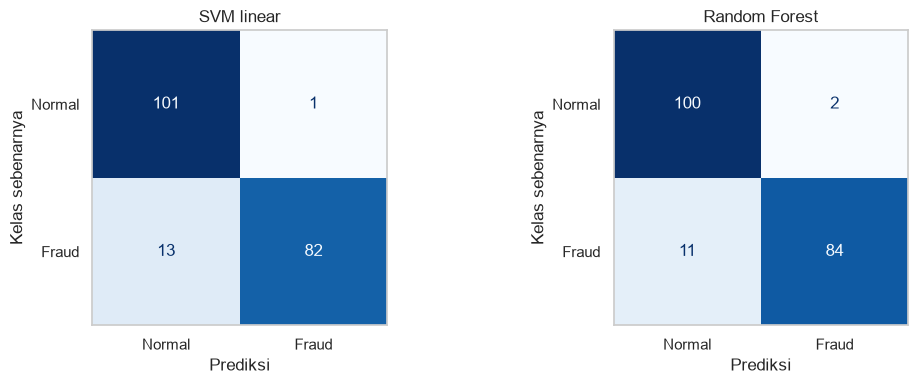

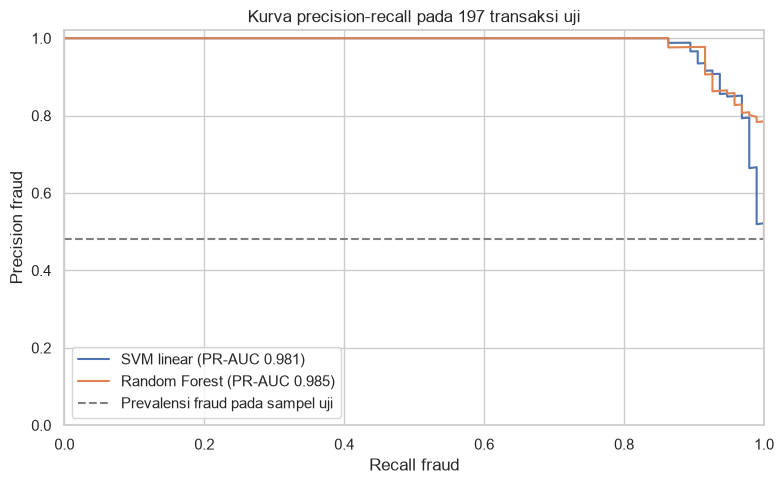

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, nama in zip(axes, pencarian):
    ConfusionMatrixDisplay.from_predictions(
        y_test, prediksi_uji[nama], labels=[0, 1], display_labels=["Normal", "Fraud"],
        cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(nama)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Kelas sebenarnya")
    ax.grid(False)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
for nama in pencarian:
    precision, recall, _ = precision_recall_curve(y_test, skor_uji[nama])
    ax.plot(recall, precision, label=f"{nama} (PR-AUC {tabel_uji.loc[nama, 'PR-AUC']:.3f})")
ax.axhline(y_test.mean(), color="gray", linestyle="--", label="Prevalensi fraud pada sampel uji")
ax.set(xlabel="Recall fraud", ylabel="Precision fraud", xlim=(0, 1), ylim=(0, 1.02),
       title="Kurva precision-recall pada 197 transaksi uji")
ax.legend(loc="lower left")
fig.tight_layout()
plt.show()

In [33]:
hasil_pilihan = tabel_uji.loc[nama_terpilih]
display(Markdown(
    f"Model pilihan **{nama_terpilih}** mendeteksi **{int(hasil_pilihan['TP'])}** dari "
    f"**{int(y_test.sum())}** fraud pada sampel uji. Ada **{int(hasil_pilihan['FN'])}** fraud "
    f"yang terlewat dan **{int(hasil_pilihan['FP'])}** transaksi normal yang salah diberi alarm. "
    f"Recall fraud **{hasil_pilihan['Recall fraud']:.1%}** dan precision fraud "
    f"**{hasil_pilihan['Precision fraud']:.1%}** berlaku pada ambang bawaan model dan subset ini. "
    "Pemilihan ambang operasional berbasis biaya memerlukan kebutuhan bisnis yang lebih terperinci."
))

Model pilihan **SVM linear** mendeteksi **82** dari **95** fraud pada sampel uji. Ada **13** fraud yang terlewat dan **1** transaksi normal yang salah diberi alarm. Recall fraud **86.3%** dan precision fraud **98.8%** berlaku pada ambang bawaan model dan subset ini. Pemilihan ambang operasional berbasis biaya memerlukan kebutuhan bisnis yang lebih terperinci.

In [34]:
tertinggi_uji = tabel_uji.drop(index="Baseline konstan")["PR-AUC"].idxmax()
display(Markdown(
    f"Pada sampel uji, PR-AUC tertinggi diperoleh **{tertinggi_uji}** "
    f"({tabel_uji.loc[tertinggi_uji, 'PR-AUC']:.4f}), sedangkan pilihan dari validasi "
    f"data latih adalah **{nama_terpilih}**. Perubahan ranking dapat terjadi antar pembagian "
    "sampel. Kedua hasil dilaporkan dan keputusan model mengikuti prosedur validasi bab 7."
))

Pada sampel uji, PR-AUC tertinggi diperoleh **Random Forest** (0.9852), sedangkan pilihan dari validasi data latih adalah **SVM linear**. Perubahan ranking dapat terjadi antar pembagian sampel. Kedua hasil dilaporkan dan keputusan model mengikuti prosedur validasi bab 7.

## 8.3 Feature importance Random Forest

Modul 7 memakai feature_importances_ untuk menyusun tabel dan barplot. Ukuran ini berasal dari penurunan impurity saat pohon membagi data. Fitur yang berkorelasi dapat berbagi skor importance. Gunakan hasilnya untuk menjelaskan perilaku model pada data latih, sambil mempertimbangkan anonimisasi fitur. Hasil evaluasi uji tetap menggunakan fitur yang dipilih sebelum pengujian.

,Importance
V14,0.1533
V10,0.1293
V4,0.1108
V12,0.1036
V17,0.0786
V11,0.0643
V16,0.0588
V3,0.0523
V2,0.0259
V9,0.0259


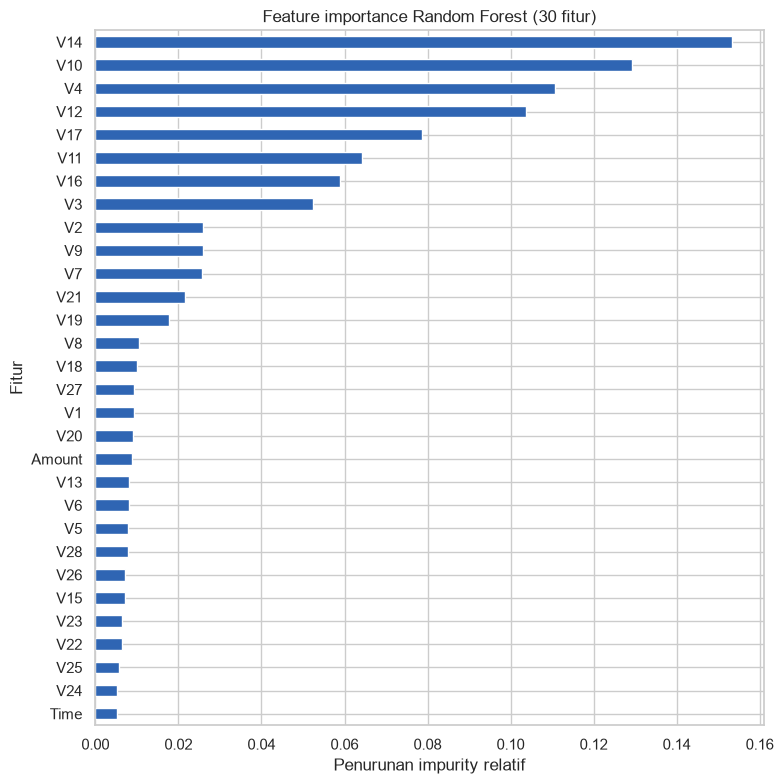

Tiga skor importance tertinggi pada Random Forest adalah **V14, V10, V4**. Komponen PCA tersebut membantu pembagian data pada pohon; arti bisnis asli tiap komponen belum tersedia.

In [35]:
importance_rf = pd.Series(
    pencarian["Random Forest"].best_estimator_.feature_importances_,
    index=X_train.columns, name="Importance",
).sort_values(ascending=False)
display(importance_rf.to_frame().round(4))
fig, ax = plt.subplots(figsize=(8, 8))
importance_rf.sort_values().plot.barh(ax=ax, color="#2F65B3")
ax.set(xlabel="Penurunan impurity relatif", ylabel="Fitur", title="Feature importance Random Forest (30 fitur)")
fig.tight_layout()
plt.show()
display(Markdown(
    "Tiga skor importance tertinggi pada Random Forest adalah **" +
    ", ".join(importance_rf.head(3).index) +
    "**. Komponen PCA tersebut membantu pembagian data pada pohon; arti bisnis asli tiap komponen belum tersedia."
))

# 9. Konklusi

Kesimpulan berikut menjawab pertanyaan pada Business Understanding dengan angka yang dihitung dari eksekusi notebook.


1. **Masalah bisnis.** Proyek menggunakan klasifikasi biner untuk membantu analis memprioritaskan transaksi berisiko fraud.
2. **Kualitas data.** Dari {len(df):,} transaksi awal, {len(df)-len(df_clean)} baris identik berlebih dihapus sehingga tersisa {len(df_clean)}. Missing value berjumlah {int(df.isna().sum().sum())}. Kandidat outlier dipertahankan dan distribusi Amount menjadi alasan preprocessing robust pada SVM.
3. **Keputusan fitur.** Tim mempertahankan 30 fitur. PR-AUC CV set lengkap {skor_lengkap_fs:.4f} dan set ringkas {skor_ringkas_fs:.4f}. Set ringkas mengurangi 21 fitur dengan selisih {selisih_fs:+.2f} poin persentase (lengkap dikurangi ringkas).
4. **Perbandingan model.** {nama_terpilih} dipilih melalui validasi silang data latih. Pada {len(y_test)} transaksi uji, model tersebut memperoleh PR-AUC {hasil_pilihan['PR-AUC']:.4f}, precision fraud {hasil_pilihan['Precision fraud']:.1%}, recall fraud {hasil_pilihan['Recall fraud']:.1%}, dan F1 {hasil_pilihan['F1 fraud']:.4f}.
5. **Makna hasil.** Pada sampel uji, {int(hasil_pilihan['TP'])} fraud terdeteksi, {int(hasil_pilihan['FN'])} fraud terlewat, dan {int(hasil_pilihan['FP'])} transaksi normal mendapat alarm keliru. Angka ini mendukung penilaian beban peninjauan analis pada sampel tersebut.
6. **Keterbatasan.** Subset diperkaya fraud, data hanya mencakup dua hari pada 2013, fitur anonim, dan identitas kartu tidak tersedia. Validasi acak dapat menilai hasil terlalu optimistis jika ada keterkaitan transaksi yang tidak teramati. Penurunan kerugian bank belum diukur.
7. **Tindak lanjut.** Uji pada distribusi fraud yang lebih realistis dan data yang lebih baru. Tetapkan biaya FP/FN, kebutuhan recall, serta kapasitas analis sebelum memilih threshold operasional.

## Kesesuaian dengan panduan dan rujukan

| Bagian panduan proyek akhir | Bukti di notebook |
|---|---|
| Business Understanding | Bab 1, pertanyaan, stakeholder, tujuan, risiko, dan metrik |
| Data Gathering | Bab 2, sumber, desain subset, dan data dictionary |
| EDA dengan interpretasi | Bab 3, statistik, distribusi, korelasi, dan penjelasan grafik |
| Cleaning dan preprocessing | Bab 4-5, audit sebelum/sesudah serta Pipeline data latih |
| Feature Selection | Bab 6, alasan per fitur dan validasi 30/10/9 fitur |
| Modeling | Bab 7, SVM dan Random Forest dari Modul 6-7 beserta parameter dan alasan |
| Evaluasi | Bab 8, tabel metrik, confusion matrix, kurva PR, dan feature importance |
| Konklusi | Bab 9, jawaban bisnis, keputusan, makna metrik, dan batasan |

**Rujukan lokal perkuliahan**

- [Panduan Proyek Akhir Praktikum Data Science 2026/2027](rujukan/panduan%20proyek/Panduan%20Proyek%20Akhir%20Praktikum%20Data%20Science%202026_2027.pdf), halaman 3-5.
- [Modul 6 SVM](rujukan/modul/Modul%206%20DS_SVM.pdf), bagian scaling, pembagian data, SVC linear, dan Pipeline, halaman 3-11.
- [Modul 7 Random Forest](rujukan/modul/Modul%207%20DS_Classification%20II.pdf), parameter dan feature importance, halaman 1-5.

**Sumber data dan dokumentasi**

- [Kaggle ULB Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud).
- [Repository proyek](https://github.com/RaflinMadani/Credit-Card-Fraud-Detection).
- [Pipeline scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html).
- [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).
- [Metrik precision-recall](https://scikit-learn.org/stable/modules/model_evaluation.html#precision-recall-f-measure-metrics).

Notebook menjadi satu berkas yang dijalankan berurutan sampai konklusi. Repository pengumpulan juga memerlukan dataset dan README yang mencantumkan anggota, kontribusi, sumber data, dependensi, serta cara menjalankan. Tanggal pengumpulan dalam panduan adalah 22 November 2026.